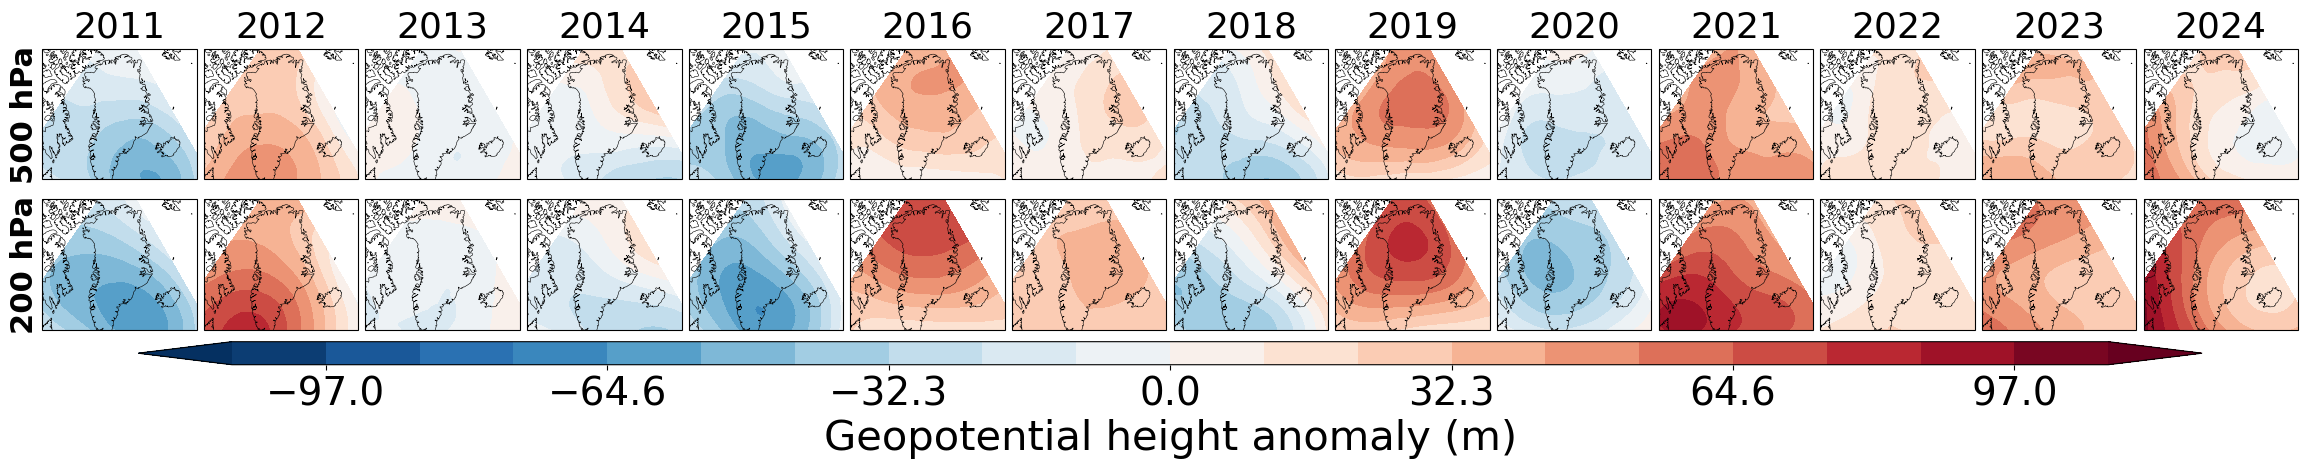

In [8]:
# -*- coding: utf-8 -*-
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# ================= 尺寸总控 =================
FONT_SIZE       = 30   
ROW_LABEL_SIZE  = 22   
YEAR_FONT_SIZE  = 26   
# ===========================================

# ========== 1) 数据处理部分 (保留你原有的逻辑) ==========
# 注意：请确保你的文件路径正确，或者依靠 except 块生成随机数据测试
file_path = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5pressure500&200pha.nc"

try:
    ds = xr.open_dataset(file_path)
    # 简单的单位换算
    z500 = ds["z"].sel(pressure_level=500) / 9.80665
    z200 = ds["z"].sel(pressure_level=200) / 9.80665
except FileNotFoundError:
    # 如果没找到文件，生成测试数据（为了代码能跑通）
    print("未找到文件，使用随机数据进行测试...")
    lons = np.arange(-180, 180, 5)
    lats = np.arange(55, 95, 2.5)
    times = [f"{y}-07-15" for y in range(2011, 2025)]
    
    # 构造 DataArray
    mock = np.random.randn(len(times), len(lats), len(lons)) * 100
    coords = {"valid_time": np.array(times, dtype='datetime64[ns]'), 
              "latitude": lats, "longitude": lons}
    
    z500 = xr.DataArray(mock, coords=coords, dims=["valid_time","latitude","longitude"])
    z200 = xr.DataArray(mock*1.5, coords=coords, dims=["valid_time","latitude","longitude"])

def anomalies_vs_clim(z_data, plot_years):
    clim = z_data.mean("valid_time")
    anos = {}
    for y in plot_years:
        # 你的筛选逻辑
        try:
            jja = z_data.sel(valid_time=z_data["valid_time"].dt.year == y).mean("valid_time")
        except Exception:
            # 备用筛选方案
            jja = z_data.sel(valid_time=z_data["valid_time"].astype(str).str.startswith(str(y))).mean("valid_time")
        anos[y] = jja - clim
    
    # 计算最大绝对值用于统一色标
    amax = max(max(abs(anos[y].max().values), abs(anos[y].min().values)) for y in plot_years)
    return anos, amax

years = list(range(2011, 2025))

# 计算异常值和最大范围 (这里定义了 ABS_MAX)
ano500, amax500 = anomalies_vs_clim(z500, years)
ano200, amax200 = anomalies_vs_clim(z200, years)
ABS_MAX = max(amax500, amax200)

# ========== 2) 画图（修正版：方形视场） ==========

# 设定投影中心
proj = ccrs.NorthPolarStereo(central_longitude=-40)

fig = plt.figure(figsize=(24, 7.2))

left, right = 0.03, 0.97
top, bottom = 0.90, 0.10

N = len(years)
gap_w = 0.003
row_height = 0.19
gap_v_ratio = 0.10
gap_v = row_height * gap_v_ratio

total_w = right - left
axes_w = (total_w - gap_w * (N - 1)) / N

y_top = top - row_height
y_bottom = y_top - gap_v - row_height

# 定义投影坐标系下的范围 (单位: 米)
# 这个范围能画出方形的格陵兰区域
EXTENT_METERS = [-1600000, 1600000, -3300000, -600000]

# --- 上排 500 hPa ---
axes_top = []
for i, y in enumerate(years):
    x0 = left + i * (axes_w + gap_w)
    ax = fig.add_axes([x0, y_top, axes_w, row_height], projection=proj)
    axes_top.append(ax)
    
    # 关键修改：指定投影坐标系范围
    ax.set_extent(EXTENT_METERS, crs=proj)
    
    ax.add_feature(cfeature.COASTLINE, linewidth=0.4, color='black', zorder=10)
    ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.2, zorder=10)
    
    # 画图
    cf = ax.contourf(
        ano500[y].longitude, ano500[y].latitude, ano500[y],
        levels=np.linspace(-ABS_MAX, ABS_MAX, 21),
        cmap="RdBu_r", extend="both", 
        transform=ccrs.PlateCarree()
    )

# 行标
axes_top[0].text(-0.02, 0.5, "500 hPa", transform=axes_top[0].transAxes,
                 ha='right', va='center', fontsize=ROW_LABEL_SIZE, weight='bold', rotation=90)

# --- 下排 200 hPa ---
axes_bot = []
for i, y in enumerate(years):
    x0 = left + i * (axes_w + gap_w)
    ax = fig.add_axes([x0, y_bottom, axes_w, row_height], projection=proj)
    axes_bot.append(ax)
    
    ax.set_extent(EXTENT_METERS, crs=proj)
    
    ax.add_feature(cfeature.COASTLINE, linewidth=0.4, color='black', zorder=10)
    ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.2, zorder=10)
    
    cf = ax.contourf(
        ano200[y].longitude, ano200[y].latitude, ano200[y],
        levels=np.linspace(-ABS_MAX, ABS_MAX, 21),
        cmap="RdBu_r", extend="both", 
        transform=ccrs.PlateCarree()
    )

# 行标
axes_bot[0].text(-0.02, 0.5, "200 hPa", transform=axes_bot[0].transAxes,
                 ha='right', va='center', fontsize=ROW_LABEL_SIZE, weight='bold', rotation=90)

# --- 标签与色条 ---
# 年份标签
for i, y in enumerate(years):
    bb = axes_top[i].get_position()
    fig.text(bb.x0 + bb.width/2, bb.y1 + 0.008, str(y),
             ha='center', va='bottom', fontsize=YEAR_FONT_SIZE)

# 色条
cbar_h = 0.032
cbar_y = y_bottom - 0.012 - cbar_h
cax = fig.add_axes([left + 0.04, cbar_y, (right - left) - 0.08, cbar_h])
cbar = fig.colorbar(cf, cax=cax, orientation="horizontal")
cbar.set_label("Geopotential height anomaly (m)", fontsize=FONT_SIZE)
cbar.ax.tick_params(labelsize=FONT_SIZE-2)

plt.show()

✅ Data range: 1950–2024 (75 years)


C:\Users\11823\AppData\Local\Temp\ipykernel_13508\3220741145.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


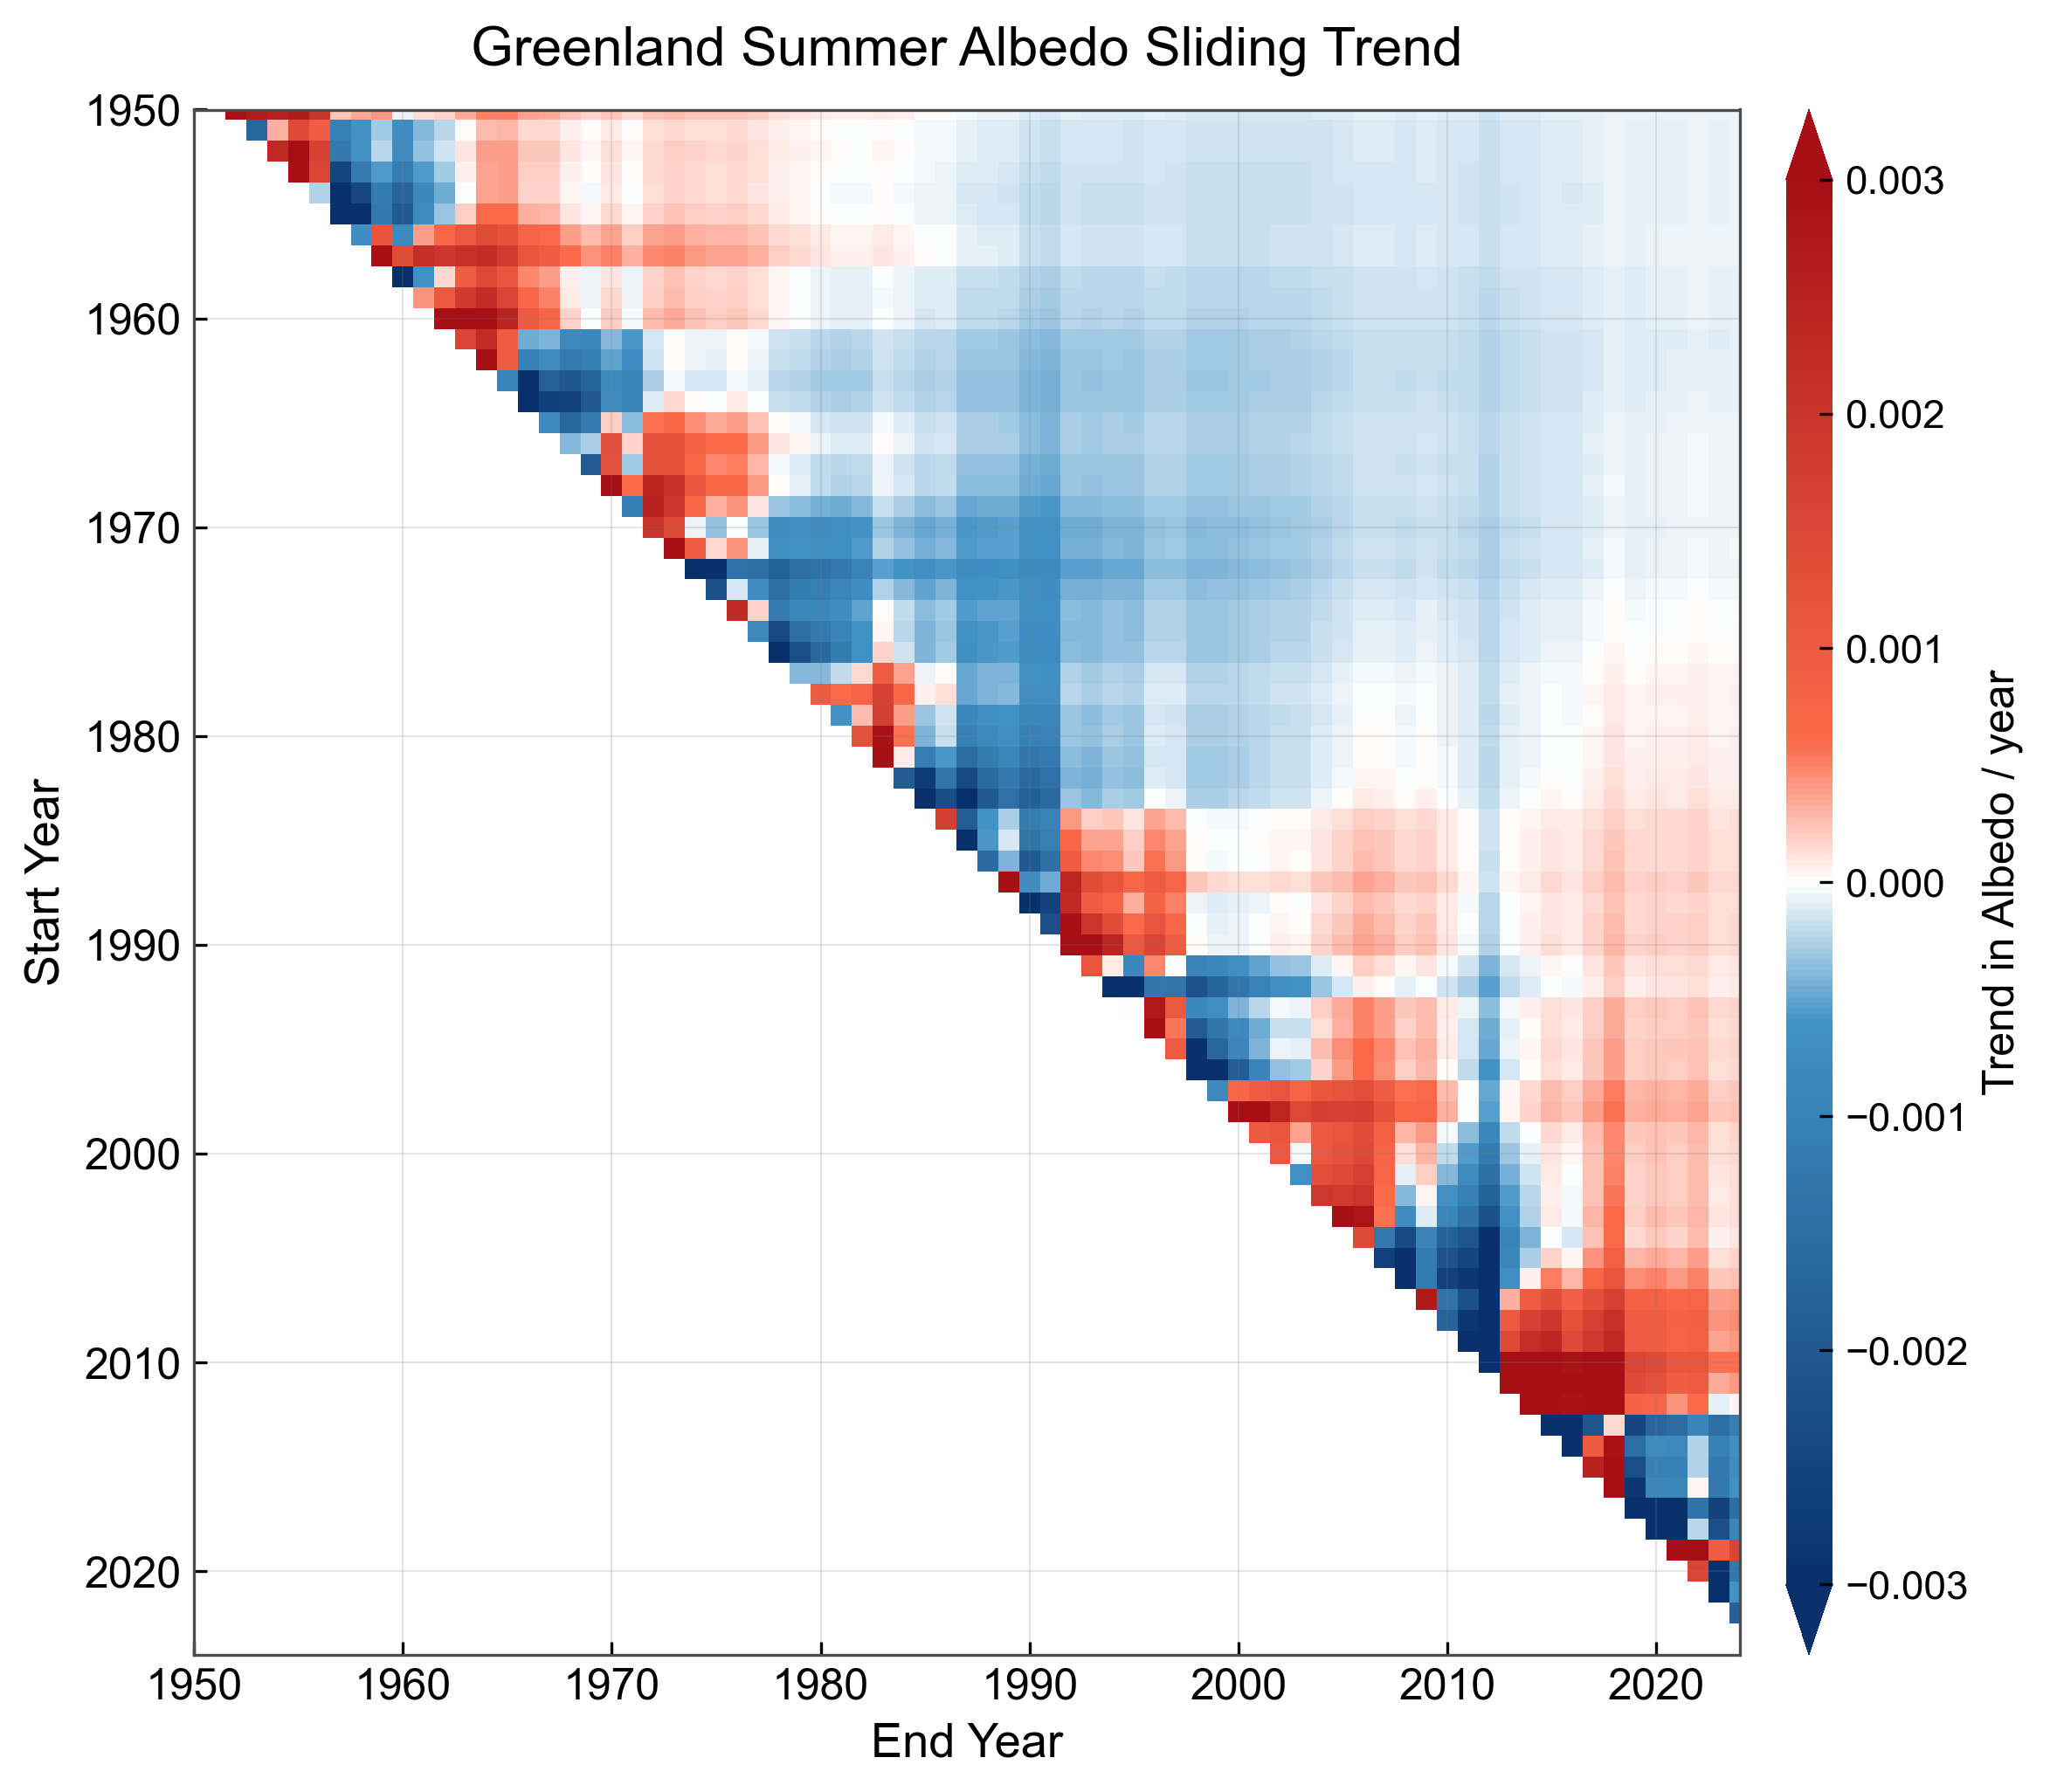

In [ ]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# ===== 路径 (Path - 请根据你的实际路径修改) =====
# 注意：你需要确保这个文件路径是正确的，并且文件存在
nc_path = r"C:\greenland\1995bu\Greenland_albedo1950-2024Summer.nc"

# ===== 1. 读取并计算格陵兰平均 Albedo =====
# 假设文件路径存在且数据结构正确
try:
    ds = xr.open_dataset(nc_path)
except FileNotFoundError:
    print(f"ERROR: File not found at {nc_path}. Please check the path.")
    exit()

# 自动识别包含“albedo”的变量名
varname = [v for v in ds.data_vars if "albedo" in v.lower()][0]
da = ds[varname]
albedo_mean = da.mean(dim=("lat", "lon"), skipna=True)

# ===== 2. 识别时间维度 =====
time_values = albedo_mean["time"].values
if np.issubdtype(time_values.dtype, np.number):
    years = np.array(time_values).astype(int)
else:
    # 提取年份
    years = pd.to_datetime(time_values).year
vals = albedo_mean.values
print(f"✅ Data range: {years.min()}–{years.max()} ({len(years)} years)")

# ===== 3. 核心修改：计算滑动趋势矩阵（右上角结构） =====
n = len(years)
# 初始化一个全为 NaN 的矩阵
trend_matrix = np.full((n, n), np.nan) 

# 外层循环: Start Year index (对应矩阵的行 i)
for i in range(n): 
    # 内层循环: End Year index (对应矩阵的列 j)
    # 确保时段长度至少为 3 年 (j - i + 1 >= 3)，所以 j >= i + 2
    for j in range(i + 2, n): 
        
        # 截取从 i 到 j (包含 j) 的年份和数据
        x = np.array(years[i:j+1]).reshape(-1, 1) # 时间变量 (自变量)
        y = vals[i:j+1]                           # Albedo 值 (因变量)
        
        # 确保有足够多的有限值来进行线性回归 (至少2个点，但我们要求至少3年)
        if np.isfinite(y).sum() >= 2: 
            model = LinearRegression().fit(x, y)
            # 将趋势值存入矩阵的 [Start Year Index, End Year Index]，即右上角
            trend_matrix[i, j] = model.coef_[0] 
        else:
            # 如果数据点不足，保持为 NaN
            trend_matrix[i, j] = np.nan

# ===== 4. 自定义色图（蓝-白-红，用于趋势） =====
# 这种色图非常适合 Nature 家族期刊风格，清晰地展示了正负趋势。
colors = [
    (0.00, "#08306b"),  # Darkest Blue
    (0.40, "#4292c6"),  # Light Blue
    (0.50, "#ffffff"),  # White Center (0)
    (0.60, "#fb6a4a"),  # Light Red
    (1.00, "#a50f15")   # Darkest Red
]
cmap = LinearSegmentedColormap.from_list("bluewhite_red_trend", colors, N=256)

# ===== 5. 绘图样式参数设置 =====
# 字体设置，推荐使用 Arial 或 Times New Roman 等通用字体
FONT_SIZE = 12 
plt.rcParams.update({
    "font.family": "Arial",
    "font.size": FONT_SIZE,
    "axes.linewidth": 0.8,
    "xtick.direction": "in", # 刻度线向内
    "ytick.direction": "in", # 刻度线向内
})

# ===== 6. 绘图 =====
# 调整 figsize 让图表看起来更宽敞
fig, ax = plt.subplots(figsize=(8.0, 7.0), dpi=300) 

# 设置颜色条的范围和中心点（对称色条的规范做法）
vmin, vmax = -0.003, 0.003
norm = TwoSlopeNorm(vmin=vmin, vcenter=0.0, vmax=vmax)

# 绘制热力图。由于 trend_matrix[i, j] 存储的是 i: Start Year, j: End Year，
# 且 Y 轴反转，所以数据显示在右上角。
pcm = ax.pcolormesh(years, years, trend_matrix,
                    cmap=cmap, norm=norm,
                    shading="auto", rasterized=True)

# ===== 7. 坐标与方向控制与刻度设置 =====
ax.set_xlim(years.min(), years.max())
# 关键：设置 Y 轴从上到下 (1950 在顶部)，与右图一致
ax.set_ylim(years.max(), years.min()) 
ax.set_aspect("equal")
ax.set_facecolor("white") # 背景色保持白色

ax.set_xlabel("End Year", fontsize=FONT_SIZE + 1)
ax.set_ylabel("Start Year", fontsize=FONT_SIZE + 1)
ax.set_title("Greenland Summer Albedo Sliding Trend", fontsize=FONT_SIZE + 3, pad=12)

# 设置主要刻度（每隔10年）
tick_years = np.arange(years.min(), years.max() + 1, 10)
ax.set_xticks(tick_years)
ax.set_yticks(tick_years)
ax.tick_params(axis='both', which='major', labelsize=FONT_SIZE)

# ===== 8. 色条（右侧对齐，等高） =====
# 使用 inset_axes 精确控制色条位置和大小
cax = inset_axes(ax, width="3%", height="100%",
                 loc="lower left",
                 bbox_to_anchor=(1.03, 0.0, 1.0, 1.0),
                 bbox_transform=ax.transAxes, borderpad=0)
# extend="both" 表示色条两端有三角，用于超范围的值
cbar = plt.colorbar(pcm, cax=cax, extend="both", 
                    ticks=np.linspace(vmin, vmax, 7)) # 增加刻度数量，更精细
cbar.set_label("Trend in Albedo / year", fontsize=FONT_SIZE)
cbar.ax.tick_params(labelsize=FONT_SIZE-1)
cbar.outline.set_visible(False) # 移除边框，更简洁

# ===== 9. 网格与版面 =====
# 移除网格线，Nature 风格图表通常不使用网格线，或使用极浅色网格
# ax.grid(False) 
# 如果需要网格，使用以下设置：
ax.grid(True, color="gray", alpha=0.2, linestyle='-', linewidth=0.5)

plt.tight_layout()
plt.show()

ds.close() # 关闭 xarray 数据集


数据集变量: ['spatial_ref', 'sf', 'tp', 'rf']


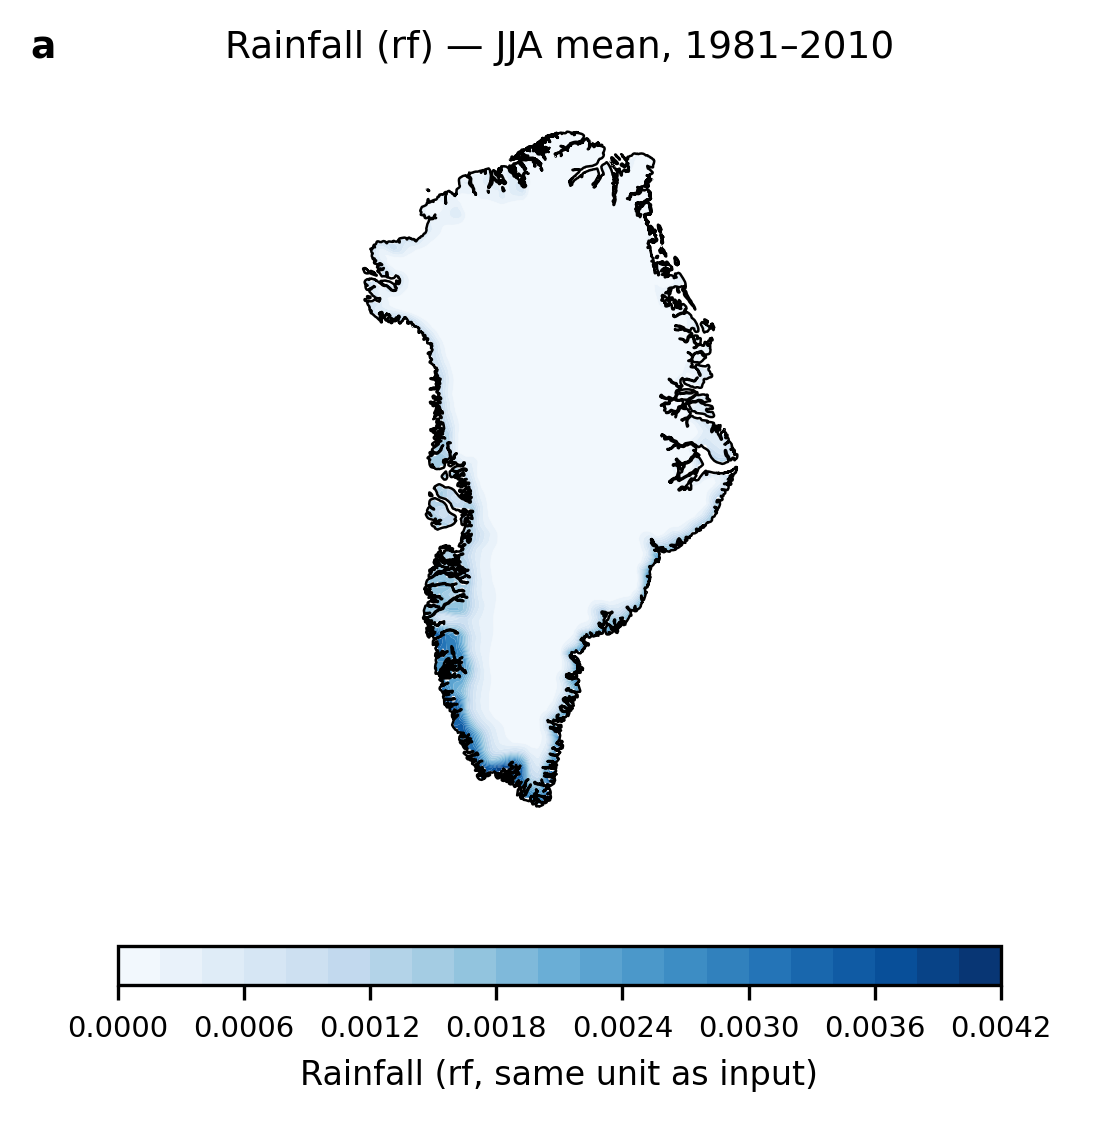

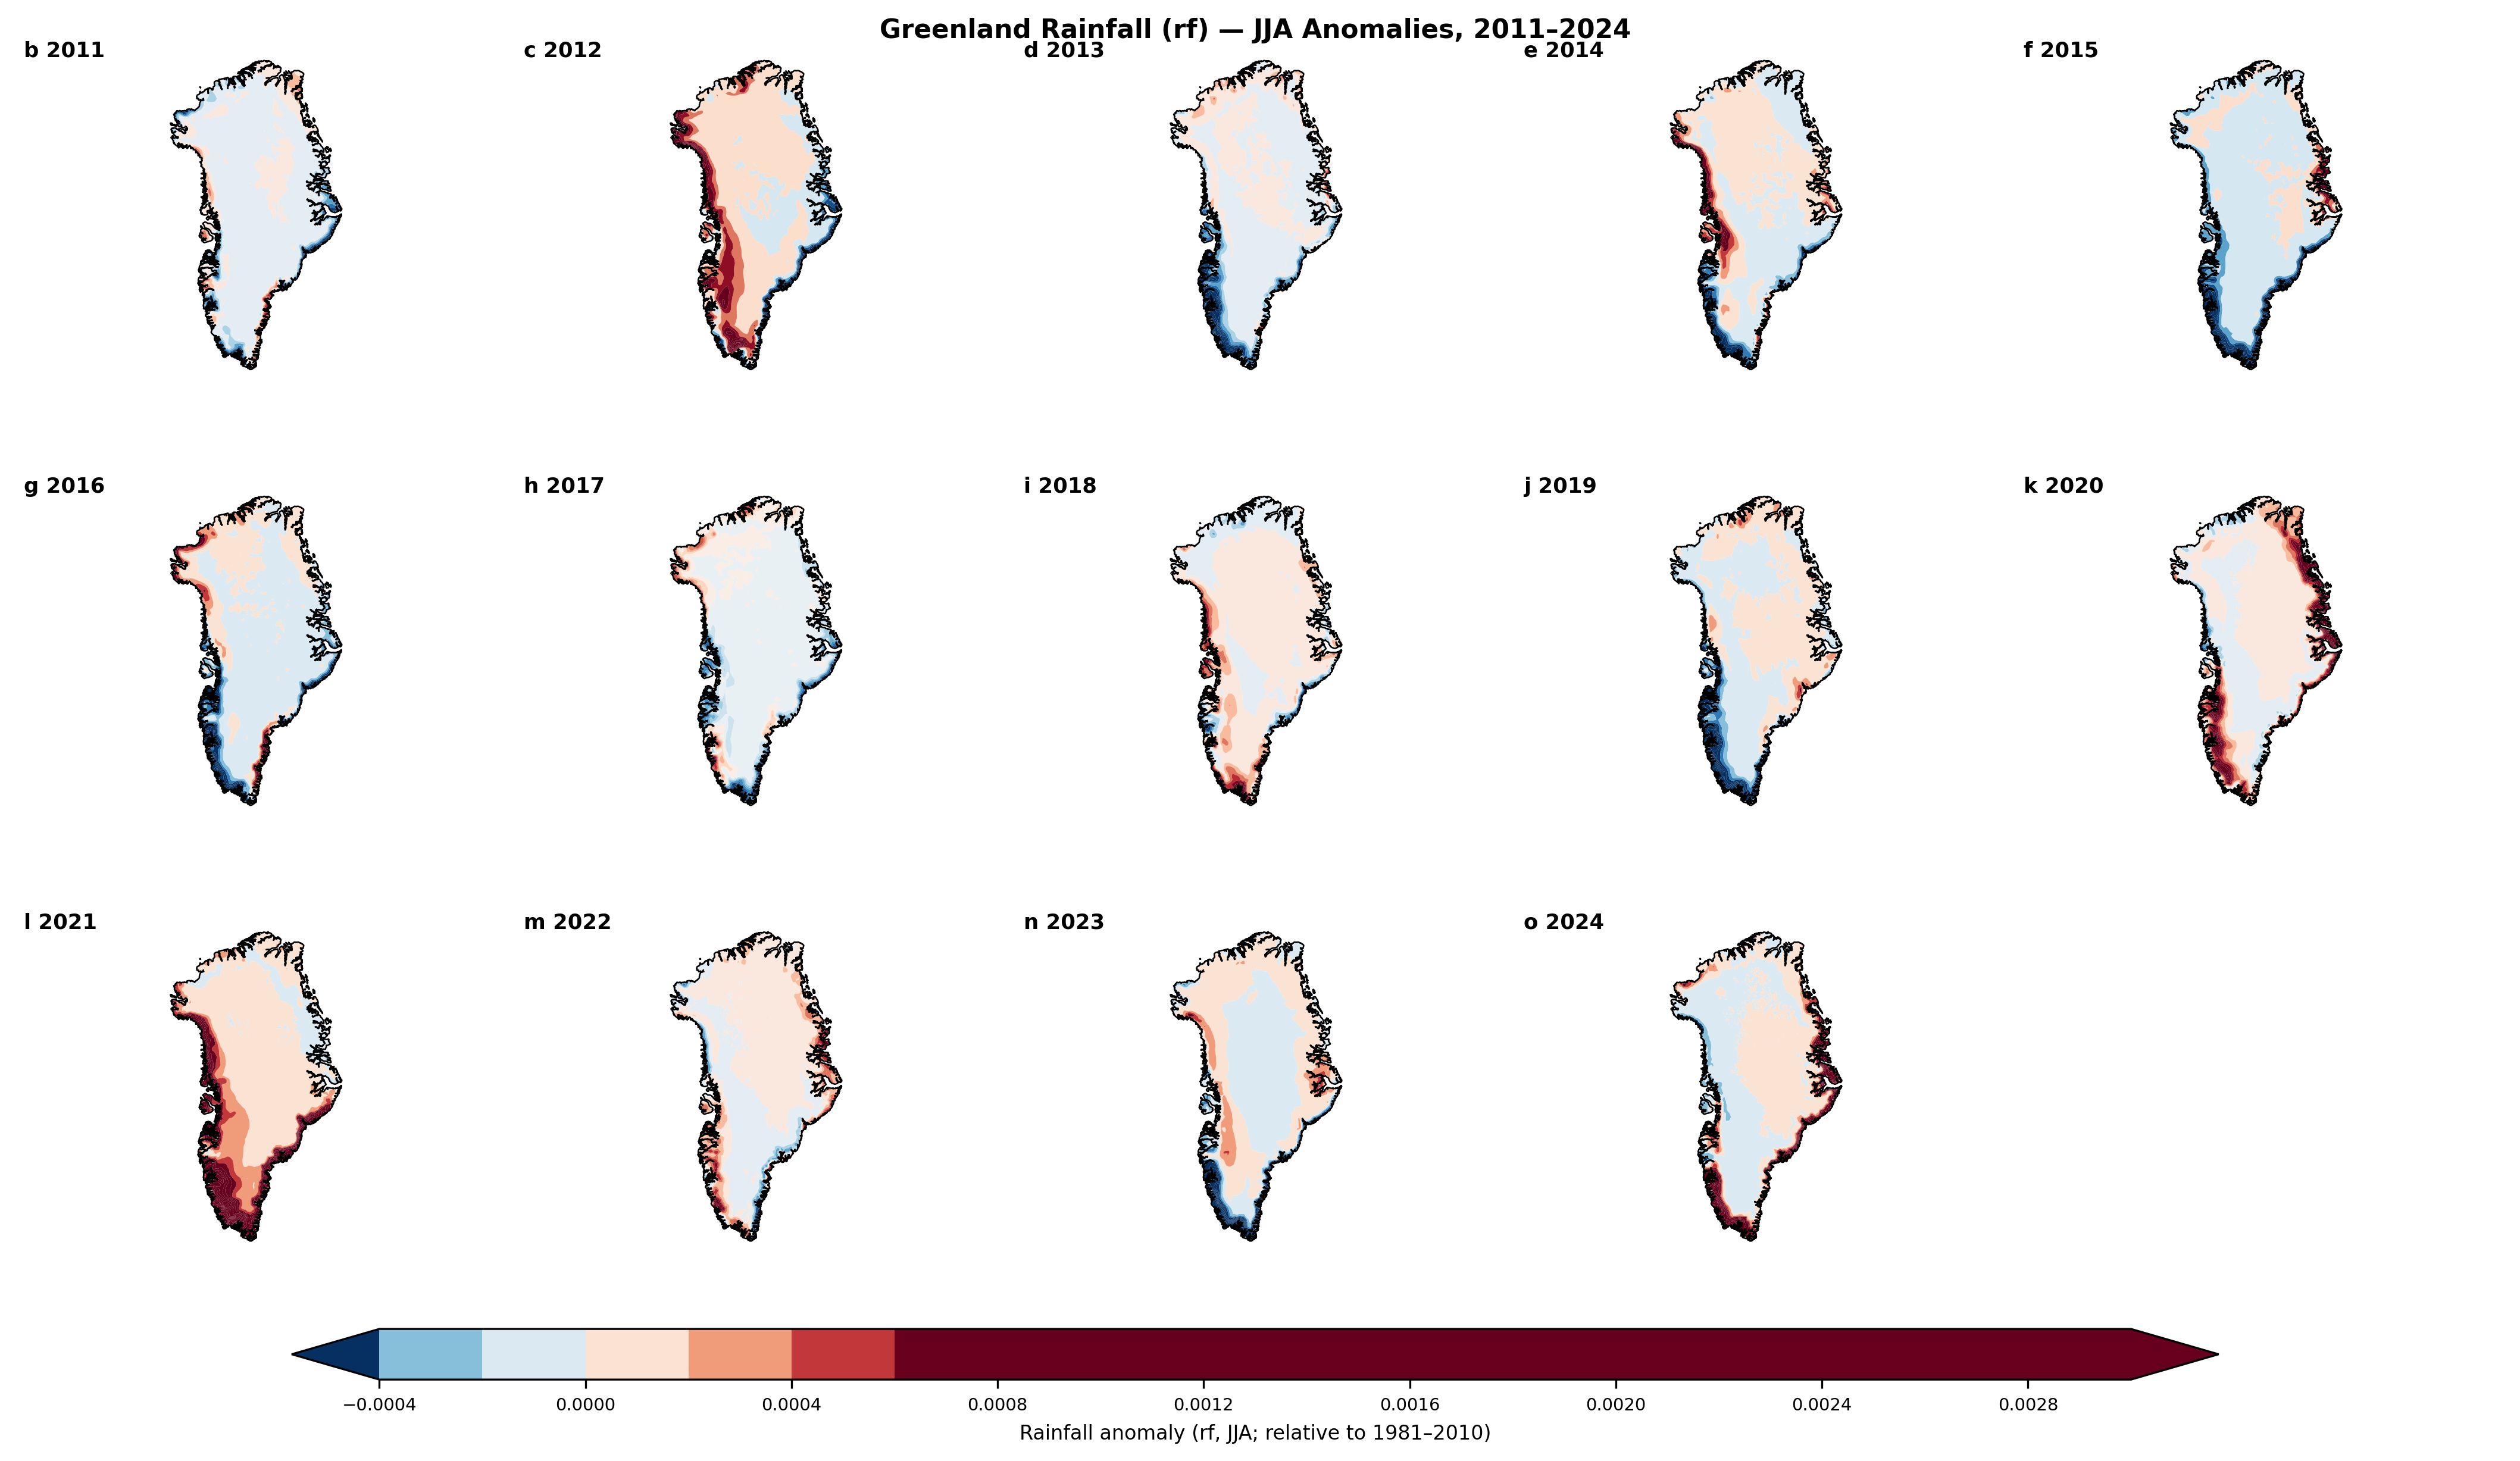

In [3]:
# -*- coding: utf-8 -*-
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.io.shapereader import Reader
from matplotlib.colors import TwoSlopeNorm

# ========== 1) 数据 ==========
nc_path = r"E:\TUB\greenland\sf_tp_rf.nc"
ds = xr.open_dataset(nc_path)
print("数据集变量:", list(ds.data_vars))
var_name = 'rf' if 'rf' in ds.data_vars else list(ds.data_vars)[0]
da = ds[var_name]

# 时间维 / 经纬度名自适应
time_dim = 'valid_time' if 'valid_time' in da.dims else ('time' if 'time' in da.dims else None)
if time_dim is None:
    raise ValueError("未找到时间维（valid_time 或 time）")

def pick_coord_names(da):
    lon = next((n for n in ['longitude','lon','x'] if n in da.coords), None)
    lat = next((n for n in ['latitude','lat','y']   if n in da.coords), None)
    if lon is None or lat is None:
        raise ValueError("未找到经纬度坐标（longitude/latitude 或 lon/lat）")
    return lon, lat
lon_name, lat_name = pick_coord_names(da)

# 投影、范围与边界
proj   = ccrs.NorthPolarStereo(central_longitude=-45)
extent = [-75, -10, 55, 85]
greenland_shp = r"E:\TUB\greenland\Greenland_shp\Gboundry.shp"
greenland_geom = list(Reader(greenland_shp).geometries())
greenland_feature = cfeature.ShapelyFeature(
    greenland_geom, ccrs.PlateCarree(), facecolor='none', edgecolor='black', linewidth=0.6
)

# ========== 2) 计算基准与距平 ==========
def compute_base_and_anoms(dataarray, years_base=(1981,2010), years_plot=range(2011,2025)):
    clim = dataarray.sel(**{time_dim: slice(f"{years_base[0]}-06-01", f"{years_base[1]}-08-31")})
    clim_monthly = clim.groupby(f"{time_dim}.month").mean(dim=time_dim)
    base_jja = clim_monthly.sel(month=[6,7,8]).mean(dim='month')
    anoms = {}
    for y in years_plot:
        summer = dataarray.sel(**{time_dim: slice(f"{y}-06-01", f"{y}-08-31")})
        summer_mean = summer.mean(dim=time_dim)
        anoms[y] = summer_mean - base_jja
    return base_jja, anoms

years = list(range(2011, 2025))  # 14 年
base_jja, anoms = compute_base_and_anoms(da, years_plot=years)

# ========== 3) 通用样式 ==========
plt.rcParams.update({
    'font.size': 8.5, 'axes.titlesize': 9, 'figure.dpi': 300,
    'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.format': 'tiff'
})

def tidy_axes(ax):
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.add_feature(greenland_feature, zorder=3)
    # 清理边框/刻度，避免空白
    for attr in ['spines']:
        obj = getattr(ax, attr, None)
        if obj:
            for s in obj.values():
                try: s.set_visible(False)
                except: pass
    ax.set_xticks([]); ax.set_yticks([])
    try: ax.set_frame_on(False)
    except: pass

# ========== 4) 基准图（更小更紧凑） ==========
fig1 = plt.figure(figsize=(4.6, 3.3))
ax = fig1.add_axes([0.02, 0.08, 0.96, 0.88], projection=proj)  # 手动轴域，极小边距
tidy_axes(ax)
ax.set_title("a", loc='left', weight='bold', fontsize=9, pad=-10)
ax.set_title("Rainfall (rf) — JJA mean, 1981–2010", fontsize=9, pad=4)

cf = ax.contourf(
    base_jja[lon_name], base_jja[lat_name], base_jja,
    levels=21, cmap='Blues', transform=ccrs.PlateCarree(), antialiased=True
)

cax = fig1.add_axes([0.18, 0.04, 0.64, 0.04])  # 极薄横向色标
cbar = fig1.colorbar(cf, cax=cax, orientation='horizontal')
cbar.set_label("Rainfall (rf, same unit as input)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

fig1.savefig("Fig1_RF_JJA_Climatology_1981-2010.tiff")
plt.show()

# ========== 5) 年度距平：3 行 × 5 列（紧凑） ==========
nrows, ncols = 3, 5
total = nrows * ncols  # 15
fig_w, fig_h = 14.2, 8.1  # 画布尺寸，保证单幅图尽可能大
fig2 = plt.figure(figsize=(fig_w, fig_h))

# 手动布局，严控空白（四边留白+行列间距都极小）
left, right, bottom, top = 0.012, 0.992, 0.10, 0.992
hspace, wspace = 0.012, 0.006
panel_w = (right - left - (ncols - 1) * wspace) / ncols
panel_h = (top - bottom - (nrows - 1) * hspace) / nrows

# 稳健、对称、零中心色标
vals = np.concatenate([np.ravel(anoms[y].values) for y in years])
vals = vals[np.isfinite(vals)]
if vals.size:
    p2, p98 = np.percentile(vals, [2, 98])
    M = max(abs(p2), abs(p98))
    vmin, vmax = -M, M
else:
    vmin, vmax = -0.1, 0.1
norm = TwoSlopeNorm(vcenter=0.0, vmin=vmin, vmax=vmax)

last = None
# 前 14 个格子放 2011–2024，第 15 个格子留空
for i, y in enumerate(years):
    r, c = divmod(i, ncols)
    x0 = left + c * (panel_w + wspace)
    y0 = top - (r + 1) * panel_h - r * hspace
    ax = fig2.add_axes([x0, y0, panel_w, panel_h], projection=proj)
    tidy_axes(ax)
    ax.text(0.012, 0.985, f"{chr(98+i)} {y}", transform=ax.transAxes,
            va='top', ha='left', fontsize=8.5, weight='bold', zorder=5)
    an = anoms[y]
    last = ax.contourf(
        an[lon_name], an[lat_name], an,
        levels=21, cmap='RdBu_r', norm=norm, extend='both',
        transform=ccrs.PlateCarree(), antialiased=True
    )

# 共享色标（窄且靠下，进一步压缩空白）
cax = fig2.add_axes([0.12, 0.055, 0.76, 0.035])
cbar = fig2.colorbar(last, cax=cax, orientation='horizontal')
cbar.set_label("Rainfall anomaly (rf, JJA; relative to 1981–2010)", fontsize=8)
cbar.ax.tick_params(labelsize=7)

# 紧凑主标题
fig2.text(0.5, 0.997, "Greenland Rainfall (rf) — JJA Anomalies, 2011–2024",
          ha='center', va='top', fontsize=10.5, weight='bold')

fig2.savefig("Fig2_RF_JJA_Anomalies_2011-2024_3x5.tiff")
plt.show()


In [7]:
# -*- coding: utf-8 -*-
"""
Generate JJA 1981-2010 climatology files for Greenland project (Part 2).

This script reads the base NetCDF files, calculates the
June-July-August (JJA) mean for the 1981-2010 period for the
variables listed in the second plotting script:
(z, t2m, rf, tcc, ssrd, alb, z500, z200)
and saves each climatology as a separate NetCDF file.
"""

import xarray as xr
import numpy as np
import os

# ==================== 文件路径 (File Paths) ====================
CLIM_DIR = r"E:\TUB"

# 从您的第二个脚本中复制的路径
file_tccsrrdz = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\tccsrrdz.nc"
file_z        = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandSP500&200pha.nc"
file_rf       = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\sf_tp_rf.nc"
file_t2m      = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc"
file_alb      = r"C:\greenland\1995bu\Greenland_albedo1950-2024.nc"

# ==================== 参数 (Parameters) ====================
CLIM_START_YEAR = 1981
CLIM_END_YEAR = 2010
CLIM_LABEL = f"JJAclim{CLIM_START_YEAR}_{CLIM_END_YEAR}"

# 确保输出目录存在 (Ensure output directory exists)
os.makedirs(CLIM_DIR, exist_ok=True)

# ==================== 辅助函数 (Helper Functions) ====================

def open_with_timefix(path):
    """
    打开文件并修正时间维度 (int 年份→datetime)
    (Copied from your second plotting script)
    """
    try:
        ds = xr.open_dataset(path)
    except Exception as e:
        print(f"Error opening file {path}: {e}")
        return None
        
    time_vars = [k for k in ds.coords if "time" in k.lower()]
    
    # 如果没有时间维度，或者时间维度已经是 datetime64，则直接返回
    if not time_vars:
        return ds
        
    tname = time_vars[0]
    if np.issubdtype(ds[tname].dtype, np.datetime64):
        # 已经是 datetime, 确保维度名称统一
        if tname != "time":
             return ds.rename({tname: "time"})
        return ds
        
    # 如果是整数年份 (例如 albedo 文件)
    if np.issubdtype(ds[tname].dtype, np.integer):
        print(f"Fixing integer time coordinate in: {path}")
        # 假设整数年份代表JJA均值，将其设置为该年7月1日
        new_time = np.array([f"{int(y)}-07-01" for y in ds[tname].values], dtype="datetime64[ns]")
        ds = ds.assign_coords({tname: new_time})
        
    # 重命名为 'time'
    return ds.rename({tname: "time"})


def calculate_and_save_climatology(
    var_name_out,   # e.g., 'z500'
    path, 
    var_in_file,    # e.g., 'z'
    long_name, 
    units, 
    scale=1.0, 
    operation='multiply', # 'multiply' or 'divide'
    special_handling=None # 'z500' or 'z200'
):
    """
    Loads a variable, calculates its 1981-2010 JJA climatology, 
    and saves it to a NetCDF file.
    """
    print(f"--- Processing: {var_name_out} ---")
    try:
        # 1. 打开数据 (Open data)
        ds = open_with_timefix(path)
        if ds is None:
            return

        # 2. 选择 DataArray (Select DataArray)
        if special_handling == 'z500':
            da = ds[var_in_file].sel(pressure_level=500)
            # 确保时间维度被正确处理 (z500/z200 可能有 'valid_time')
            if "valid_time" in da.dims:
                da = da.rename({"valid_time": "time"})
        elif special_handling == 'z200':
            da = ds[var_in_file].sel(pressure_level=200)
            if "valid_time" in da.dims:
                da = da.rename({"valid_time": "time"})
        else:
            if var_in_file not in ds:
                 # 尝试模糊匹配 (e.g., t2m vs temperature_2m)
                 matches = [k for k in ds.data_vars if var_in_file.lower() in k.lower()]
                 if not matches:
                    print(f"Error: Variable '{var_in_file}' not found in {path}")
                    return
                 var_in_file_actual = matches[0]
                 print(f"Found '{var_in_file_actual}' for requested '{var_in_file}'")
                 da = ds[var_in_file_actual]
            else:
                 da = ds[var_in_file]

        # 3. 应用尺度转换 (Apply scaling)
        if operation == 'divide':
            da = da / scale
        elif operation == 'multiply':
            da = da * scale
            
        print(f"Loaded and scaled data for {var_name_out}.")

        # 4. 选择 climatology 周期 (Select climatology period)
        clim_period_da = da.sel(time=slice(f"{CLIM_START_YEAR}-01-01", f"{CLIM_END_YEAR}-12-31"))
        
        # 5. 筛选JJA月份 (Filter for JJA months)
        # 'isin' is a robust way to select months
        is_jja = clim_period_da.time.dt.month.isin([6, 7, 8])
        jja_da = clim_period_da.where(is_jja, drop=True)
        
        if jja_da.time.size == 0:
            print(f"Warning: No JJA data found for {var_name_out} in the period {CLIM_START_YEAR}-{CLIM_END_YEAR}.")
            print("Please check your input files and paths.")
            return

        # 6. 计算均值 (Calculate mean over all JJA time steps)
        climatology = jja_da.mean("time", skipna=True)
        
        # 7. 添加元数据 (Add metadata for clarity)
        climatology.name = var_name_out
        climatology.attrs['long_name'] = long_name
        climatology.attrs['units'] = units
        climatology.attrs['climatology_period'] = f"JJA {CLIM_START_YEAR}-{CLIM_END_YEAR}"
        climatology.attrs['source_file'] = path
        
        # 8. 定义输出路径并保存 (Define output path and save)
        output_filename = f"Greenland_{var_name_out}_{CLIM_LABEL}.nc"
        output_path = os.path.join(CLIM_DIR, output_filename)
        
        climatology.to_netcdf(output_path)
        print(f"Successfully saved: {output_path}\n")

    except Exception as e:
        print(f"Error processing {var_name_out}: {e}\n")

# =================== 主程序 (Main Program) ===================

print("Starting climatology generation (Part 2)...")
print(f"Output directory: {CLIM_DIR}")

# 定义所有需要处理的变量
# (Matches the variables and scaling from your second plotting script)
variables_to_process = [
    {
        'name': 'z500', 
        'path': file_z, 
        'var_in_file': 'z',
        'long': '500 hPa Geopotential Height', 
        'unit': 'm',
        'scale': 9.80665,
        'op': 'divide',
        'special': 'z500'
    },
    {
        'name': 'z200', 
        'path': file_z, 
        'var_in_file': 'z',
        'long': '200 hPa Geopotential Height', 
        'unit': 'm',
        'scale': 9.80665,
        'op': 'divide',
        'special': 'z200'
    },
    {
        'name': 'z', 
        'path': file_tccsrrdz, 
        'var_in_file': 'z',
        'long': 'Surface Geopotential', 
        'unit': 'm² s⁻²',
        'scale': 1.0,
        'op': 'multiply'
    },
    {
        'name': 't2m', 
        'path': file_t2m, 
        'var_in_file': 't2m',
        'long': '2m Temperature', 
        'unit': 'K',
        'scale': 1.0,
        'op': 'multiply'
    },
    {
        'name': 'rf', 
        'path': file_rf, 
        'var_in_file': 'rf',
        'long': 'Rainfall Flux', 
        'unit': 'mm day⁻¹ * e⁻⁴', # As per your script
        'scale': 1e4,
        'op': 'multiply'
    },
    {
        'name': 'tcc', 
        'path': file_tccsrrdz, 
        'var_in_file': 'tcc',
        'long': 'Total Cloud Cover', 
        'unit': 'fraction',
        'scale': 1.0,
        'op': 'multiply'
    },
    {
        'name': 'ssrd', 
        'path': file_tccsrrdz, 
        'var_in_file': 'ssrd',
        'long': 'Surface Solar Radiation Downwards', 
        'unit': 'J m⁻² * e6', # As per your script
        'scale': 1e6,
        'op': 'divide' # Note: division
    },
    {
        'name': 'alb', 
        'path': file_alb, 
        'var_in_file': 'albedo',
        'long': 'Albedo', 
        'unit': 'fraction',
        'scale': 1.0,
        'op': 'multiply'
    }
]

# 循环处理所有变量
for var_info in variables_to_process:
    calculate_and_save_climatology(
        var_name_out=var_info['name'],
        path=var_info['path'],
        var_in_file=var_info['var_in_file'],
        long_name=var_info['long'],
        units=var_info['unit'],
        scale=var_info['scale'],
        operation=var_info['op'],
        special_handling=var_info.get('special', None)
    )

print("Climatology generation (Part 2) complete.")

Starting climatology generation (Part 2)...
Output directory: E:\TUB
--- Processing: z500 ---
Loaded and scaled data for z500.
Successfully saved: E:\TUB\Greenland_z500_JJAclim1981_2010.nc

--- Processing: z200 ---
Loaded and scaled data for z200.
Successfully saved: E:\TUB\Greenland_z200_JJAclim1981_2010.nc

--- Processing: z ---
Fixing integer time coordinate in: C:\Users\greenlandProject\ERA5LAND\ProcessFile\tccsrrdz.nc
Loaded and scaled data for z.
Successfully saved: E:\TUB\Greenland_z_JJAclim1981_2010.nc

--- Processing: t2m ---
Loaded and scaled data for t2m.
Successfully saved: E:\TUB\Greenland_t2m_JJAclim1981_2010.nc

--- Processing: rf ---
Loaded and scaled data for rf.
Successfully saved: E:\TUB\Greenland_rf_JJAclim1981_2010.nc

--- Processing: tcc ---
Fixing integer time coordinate in: C:\Users\greenlandProject\ERA5LAND\ProcessFile\tccsrrdz.nc
Loaded and scaled data for tcc.
Successfully saved: E:\TUB\Greenland_tcc_JJAclim1981_2010.nc

--- Processing: ssrd ---
Fixing intege

Calculating anomalies (optimized file handling)...
Processing C:\Users\greenlandProject\ERA5LAND\ProcessFile\tccsrrdz.nc
Closed C:\Users\greenlandProject\ERA5LAND\ProcessFile\tccsrrdz.nc
Processing C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandSP500&200pha.nc
Closed C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandSP500&200pha.nc
Processing C:\Users\greenlandProject\ERA5LAND\ProcessFile\sf_tp_rf.nc
Closed C:\Users\greenlandProject\ERA5LAND\ProcessFile\sf_tp_rf.nc
Processing C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc
Closed C:\Users\greenlandProject\ERA5LAND\ProcessFile\greenlandT2M.nc
Processing C:\greenland\1995bu\Greenland_albedo1950-2024.nc
Closed C:\greenland\1995bu\Greenland_albedo1950-2024.nc
Processing C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc
Closed C:\Users\greenlandProject\ERA5LAND\ProcessFile\GreenlandhclcVIMF.nc
Processing C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland202209.nc for STRD

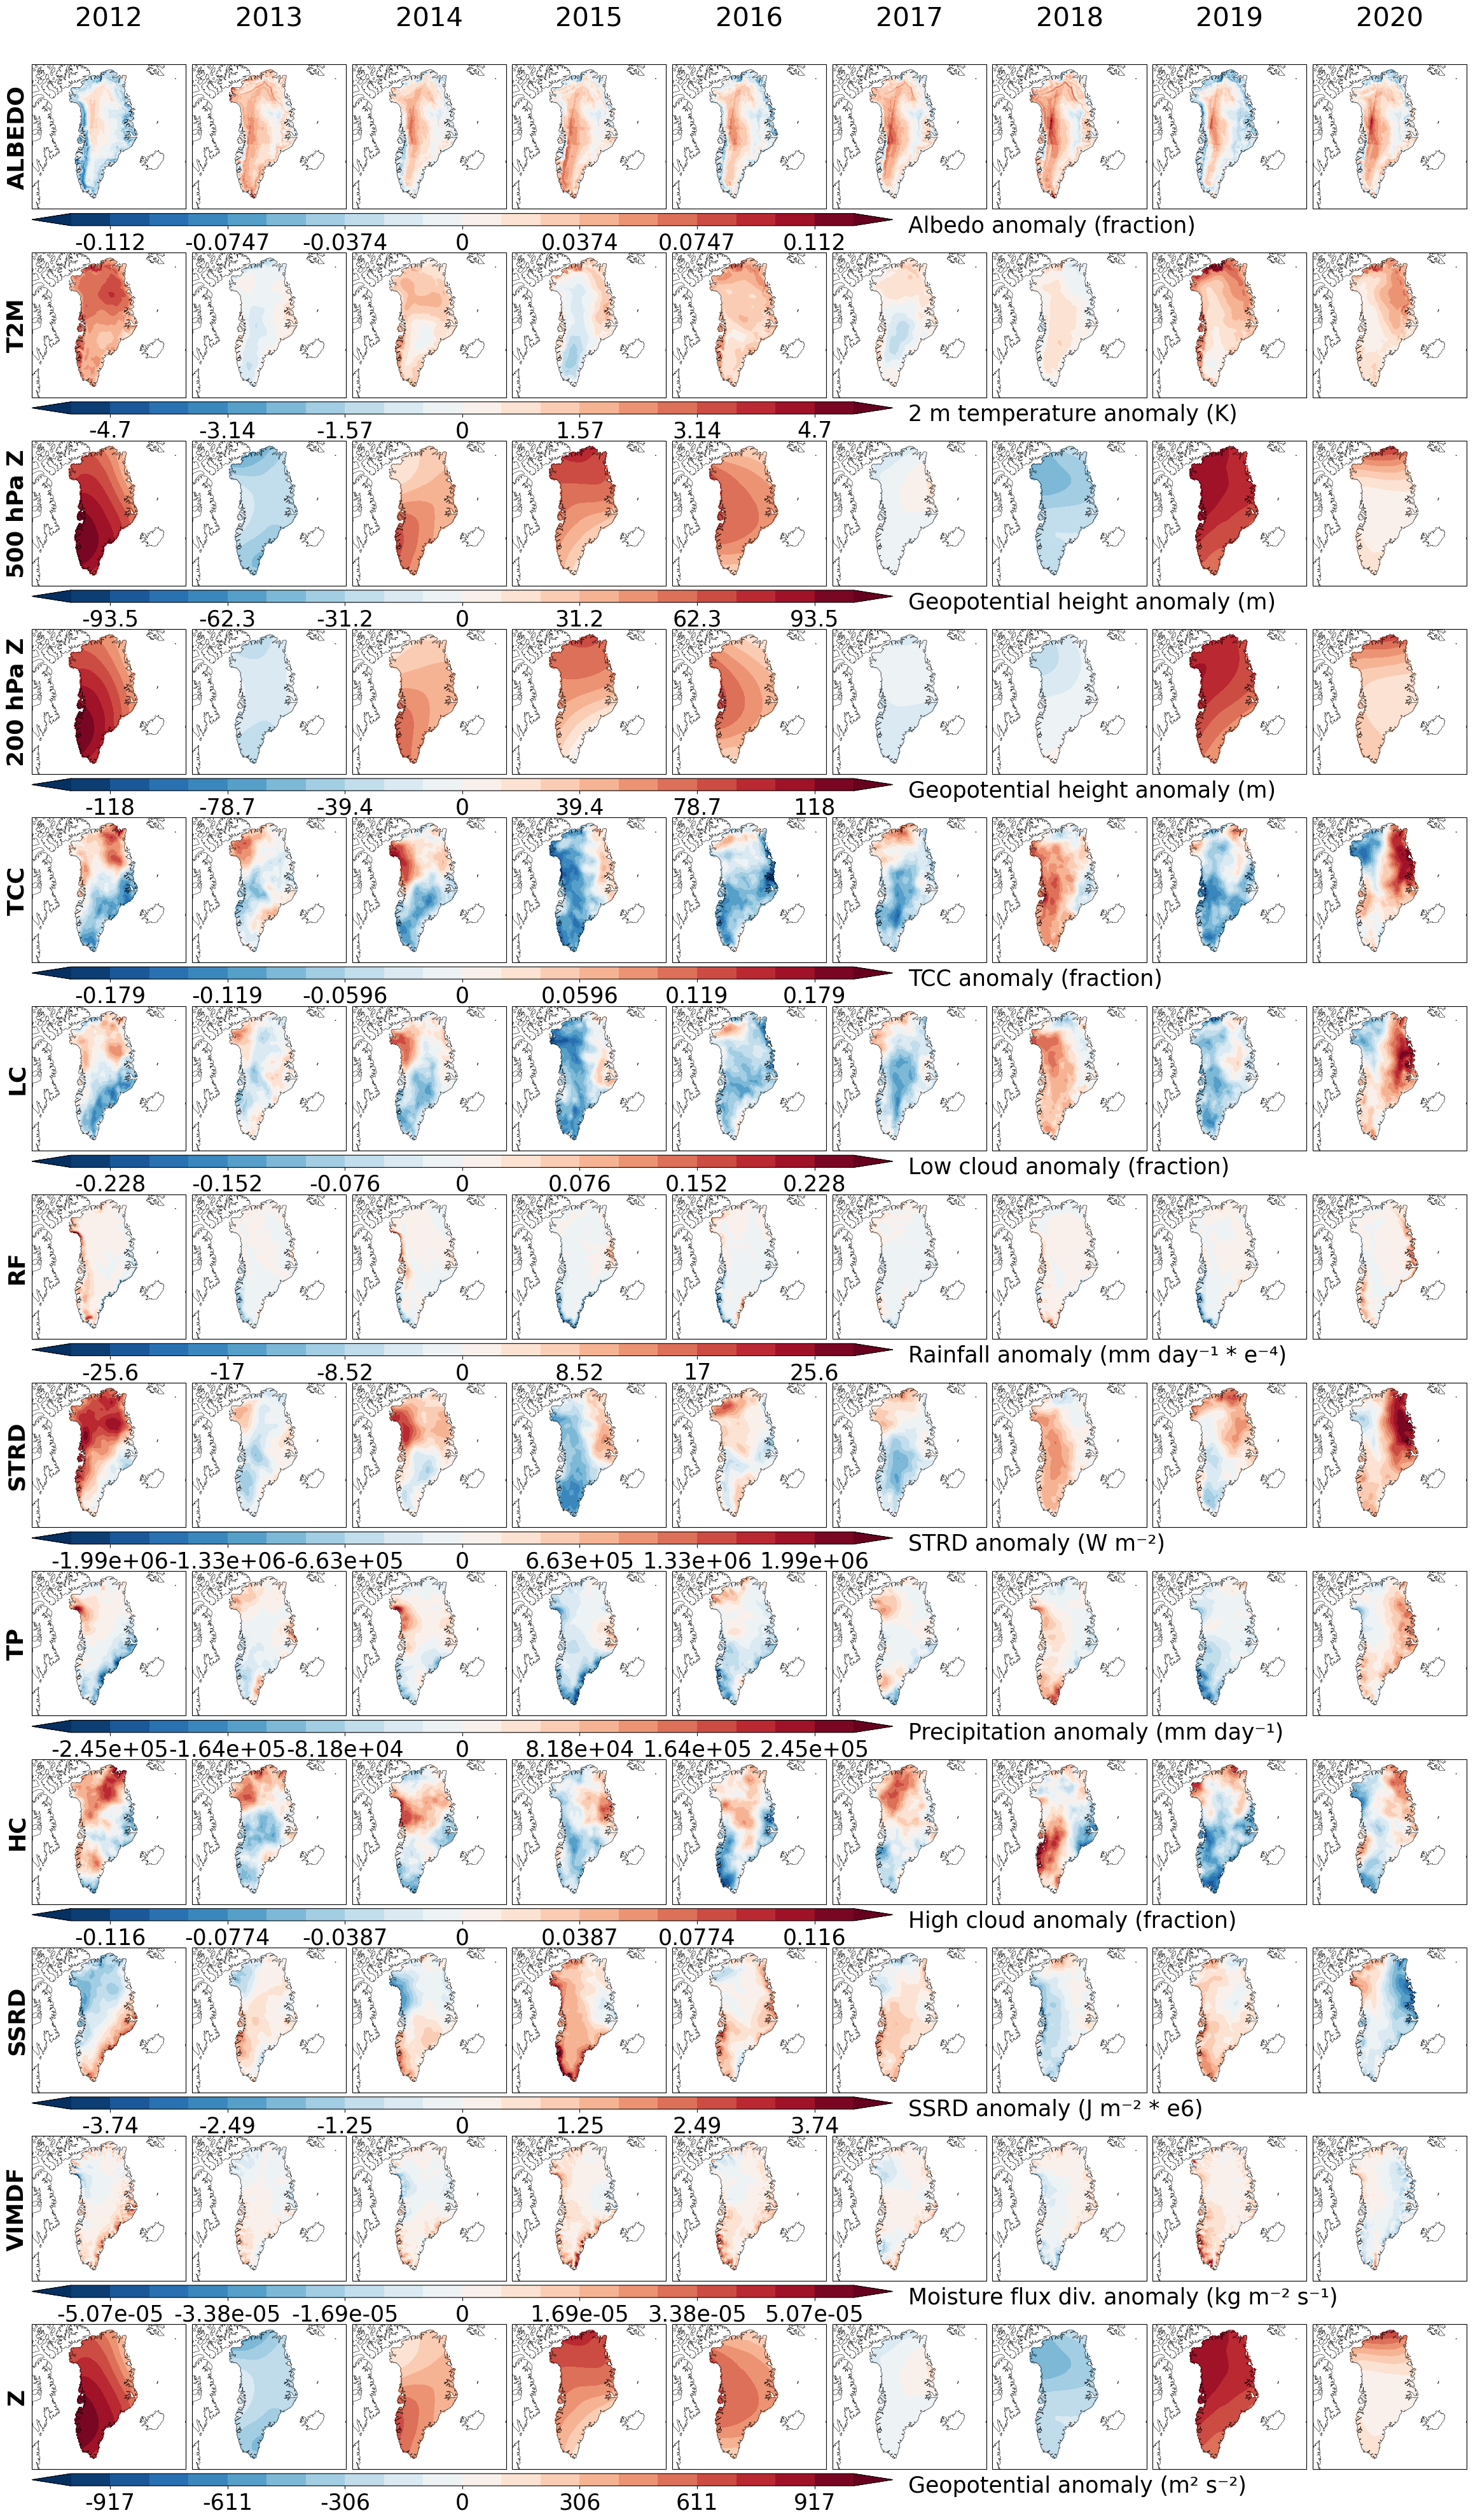

Done.


In [1]:
# -*- coding: utf-8 -*-
"""
Greenland JJA anomalies (2012–2020) - 13 Variables (新增 STRD)
- 动态计算 (1981-2010) JJA 气候态
- [优化] 使用 'with' 语句确保文件被及时关闭
- [修正] 使用正确的变量名 lcc 和 hcc
- [布局-V6] 水平色标在下方
- [布局-V6] 增加 ROW_GAP 和 CBAR_PAD 以防止标签重叠
- [布局-V6] 下调色标右侧标签的 Y 坐标
- 绘图顺序: ALBEDO → T2M → Z500 → Z200 → TCC → LC → RF → STRD → Others
"""

import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os

# ==================== 参数设置 ====================
years = list(range(2012, 2021))
clim_years = range(1981, 2011) # 1981-2010

# --- 绘图布局 ---
FIG_W = 24
# --- [!! 布局修正 V6 !!] ---
# 基于 13 个变量重新计算 FIG_H
# Plot Height: 24 * 0.12 = 2.88"
# Cbar Height: 24 * 0.008 = 0.192"
# Cbar Pad: 24 * 0.003 = 0.072"
# Row Gap: 24 * 0.005 = 0.12"
# Total per row: 3.264"
# Total 13 rows: 13 * 3.264 = 42.432". 圆整为 43"
FIG_H = 43 # <--- **FIG_H 调整为 43**

EXTENT = [-65, -12, 58, 84]
CENTRAL_LON = -40

# --- [!! 布局修正 V6 !!] ---
# 为 FIG_H=43 重新计算相对参数
ROW_H    = 2.88 / FIG_H  # (约 0.067)
CBAR_H   = 0.192 / FIG_H # (约 0.0044)
CBAR_PAD = 0.072 / FIG_H # (约 0.0017)
ROW_GAP  = 0.12 / FIG_H  # (约 0.0028)

# --- 字体 ---
ROW_LABEL_SIZE = 26
YEAR_FONT_SIZE = 30
CBAR_LABEL_SIZE = 25
CBAR_TICK_SIZE = 25

# ==================== 文件路径 ====================
BASE_DIR = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile"

file_tccsrrdz = os.path.join(BASE_DIR, "tccsrrdz.nc")
file_z        = os.path.join(BASE_DIR, "greenlandSP500&200pha.nc")
file_rf_tp    = os.path.join(BASE_DIR, "sf_tp_rf.nc") 
file_t2m      = os.path.join(BASE_DIR, "greenlandT2M.nc")
file_hclcvimdf= os.path.join(BASE_DIR, "GreenlandhclcVIMF.nc") 
file_alb      = r"C:\greenland\1995bu\Greenland_albedo1950-2024.nc"
# --- [!! 新增文件路径 !!] ---
file_strd     = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\ERA5LANDfeature_greenland202209.nc" 

# ==================== 通用函数 (保持不变) ====================
def open_with_timefix(path):
    """打开文件并修正时间维度 (int 年份→datetime, valid_time→time)"""
    ds = xr.open_dataset(path)
    time_vars = [k for k in ds.coords if "time" in k.lower() or "valid_time" in k.lower()]
    
    if not time_vars: return ds
    tname = time_vars[0]
    
    if 'valid_time' in tname.lower():
        ds = ds.rename({'valid_time': 'time'})
        tname = 'time'
    
    if np.issubdtype(ds[tname].dtype, np.integer):
        ds[tname] = np.array([f"{int(y)}-07-01" for y in ds[tname].values], dtype="datetime64[ns]")
    
    if tname != 'time':
        ds = ds.rename({tname: 'time'})
        
    return ds

def anomalies_vs_clim(da, target_years, clim_years_range):
    """
    根据时间类型自动计算距平
    """
    if da.name is None: da.name = "unknown_var"
        
    if np.issubdtype(da["time"].dtype, np.datetime64):
        n_unique_years = len(np.unique(da["time"].dt.year))
        
        if n_unique_years < len(da["time"]):
            da_jja = da.sel(time=da["time"].dt.month.isin([6,7,8]))
        else:
            da_jja = da
        
        clim_selector = da_jja["time"].dt.year.isin(clim_years_range)
        clim_data = da_jja.sel(time=clim_selector)
        
        if clim_data.time.size == 0:
            print(f"Error: No climatology data found for {da.name} in years {list(clim_years_range)}")
            return {}, 1.0
            
        clim = clim_data.mean("time", skipna=True).load()
        clim_data.close() 
        
        anos = {}
        for y in target_years:
            year_selector = (da_jja["time"].dt.year == y)
            year_data = da_jja.sel(time=year_selector)
            if year_data.time.size > 0:
                anos[y] = (year_data.mean("time", skipna=True) - clim).load()
            else:
                print(f"Warning: No data for year {y} in {da.name}")
        
        valid_anos = [anos[y] for y in anos if y in anos and anos[y].size > 0]
        if not valid_anos:
            print(f"Error: No anomaly data calculated for {da.name}")
            return {}, 1.0
            
        vmax = np.nanmax(np.abs([float(a.max()) for a in valid_anos]))
        return anos, vmax
    else:
        raise ValueError(f"time in {da.name} 不是 datetime64，检查输入数据")

# ==================== 1. 逐个计算距平 (全部13个) ====================
print("Calculating anomalies (optimized file handling)...")

# --- 文件 1: tcc, ssrd, z ---
with open_with_timefix(file_tccsrrdz) as ds:
    print(f"Processing {file_tccsrrdz}")
    ano_tcc, vmax_tcc = anomalies_vs_clim(ds["tcc"], years, clim_years)
    ssrd_scaled = ds["ssrd"] / 1e6
    ssrd_scaled.name = "ssrd_scaled"
    ano_ssrd, vmax_ssrd = anomalies_vs_clim(ssrd_scaled, years, clim_years)
    ano_z, vmax_z     = anomalies_vs_clim(ds["z"], years, clim_years)
print(f"Closed {file_tccsrrdz}")

# --- 文件 2: z500, z200 ---
with open_with_timefix(file_z) as ds:
    print(f"Processing {file_z}")
    z500 = (ds["z"].sel(pressure_level=500) / 9.80665)
    z500.name = "z500"
    ano500, vmax500 = anomalies_vs_clim(z500, years, clim_years)
    z200 = (ds["z"].sel(pressure_level=200) / 9.80665)
    z200.name = "z200"
    ano200, vmax200 = anomalies_vs_clim(z200, years, clim_years)
print(f"Closed {file_z}")

# --- 文件 3: rf, tp ---
with open_with_timefix(file_rf_tp) as ds:
    print(f"Processing {file_rf_tp}")
    rf  = ds["rf"] * 1e4
    rf.name = "rf_scaled"
    ano_rf, vmaxrf  = anomalies_vs_clim(rf,  years, clim_years)
    tp = ds["tp"] * 1000 * 86400
    tp.name = "tp_scaled"
    ano_tp, vmax_tp   = anomalies_vs_clim(tp,  years, clim_years)
print(f"Closed {file_rf_tp}")

# --- 文件 4: t2m ---
with open_with_timefix(file_t2m) as ds:
    print(f"Processing {file_t2m}")
    ano_t2m, vmaxt2m = anomalies_vs_clim(ds["t2m"], years, clim_years)
print(f"Closed {file_t2m}")

# --- 文件 5: alb ---
with open_with_timefix(file_alb) as ds:
    print(f"Processing {file_alb}")
    ano_alb, vmax_alb = anomalies_vs_clim(ds["albedo"], years, clim_years)
print(f"Closed {file_alb}")

# --- 文件 6: hcc, lcc, vimdf ---
with open_with_timefix(file_hclcvimdf) as ds:
    print(f"Processing {file_hclcvimdf}")
    ano_lc, vmax_lc   = anomalies_vs_clim(ds["lcc"],  years, clim_years)
    ano_hc, vmax_hc   = anomalies_vs_clim(ds["hcc"],  years, clim_years)
    ano_vimdf, vmax_vimdf= anomalies_vs_clim(ds["vimdf"], years, clim_years)
print(f"Closed {file_hclcvimdf}")

# --- [!! 新增 STRD 文件处理 !!] ---
with open_with_timefix(file_strd) as ds:
    print(f"Processing {file_strd} for STRD")
    # 假设变量名就是 'strd'
    # 假设 STRD 的单位是 J/m2，如果需要转换 W/m2 (日平均)，
    # 则需要 / (86400 * 3) (JJA平均) 或 / 86400 (日平均)
    # 此处假设数据是 daily/monthly mean W/m2 或在 clim 计算中已正确处理单位
    strd = ds["strd"] 
    strd.name = "strd"
    ano_strd, vmax_strd = anomalies_vs_clim(strd, years, clim_years)
print(f"Closed {file_strd}")
# -----------------------------------

print("Anomaly calculation complete.")

# ==================== 2. 绘图 (保持不变) ====================
proj = ccrs.NorthPolarStereo(central_longitude=CENTRAL_LON)
# fig = plt.figure(figsize=(FIG_W, FIG_H)) # 保持 figure 创建不变

# --- 布局参数 ---
left, right = 0.03, 0.97
# top = 0.99 # 保持 top 不变
top = 0.99
gap_w = 0.004
N = len(years)
ax_w = (right - left - gap_w * (N - 1)) / N

def plot_row(y_top, anodict, vmax, label_text, cbar_label, fmt="%.3g"):
    # ... (plot_row 函数主体不变) ...
    global ROW_H, CBAR_H, CBAR_PAD, ROW_GAP
    
    vmax = max(abs(vmax), 1e-9) 
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    axes = []
    
    if not anodict:
        print(f"Skipping plot for {label_text} as no anomaly data was found.")
        return y_top - (ROW_H + CBAR_PAD + CBAR_H + ROW_GAP) # 保持布局

    cf_data_exists = False
    
    for i, y in enumerate(years):
        x0 = left + i * (ax_w + gap_w)
        ax = fig.add_axes([x0, y_top - ROW_H, ax_w, ROW_H], projection=proj)
        ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
        ax.add_feature(cfeature.BORDERS, linestyle=":", linewidth=0.3)
        ax.set_xticks([]); ax.set_yticks([])
        axes.append(ax)

        if y in anodict and anodict[y].size > 0:
            data = anodict[y]
            lon_name = "lon" if "lon" in data.coords else "longitude"
            lat_name = "lat" if "lat" in data.coords else "latitude"
            
            if not np.all(np.isnan(data)):
                cf = ax.contourf(
                    data[lon_name], data[lat_name], data,
                    levels=np.linspace(-vmax, vmax, 21),
                    cmap="RdBu_r", norm=norm, extend="both",
                    transform=ccrs.PlateCarree()
                )
                cf_data_exists = True 
            else:
                ax.text(0.5, 0.5, 'All NaN', ha='center', va='center', 
                        transform=ax.transAxes, fontsize=15, color='gray')
        else:
            ax.text(0.5, 0.5, 'No Data', ha='center', va='center', 
                    transform=ax.transAxes, fontsize=15, color='gray')

    # 行标签
    axes[0].text(-0.025, 0.5, label_text, transform=axes[0].transAxes,
                 ha='right', va='center', fontsize=ROW_LABEL_SIZE,
                 weight='bold', rotation=90)

    # --- 水平色标 ---
    if cf_data_exists:
        first_ax_pos = axes[0].get_position()
        cbar_y0 = first_ax_pos.y0 - CBAR_PAD - CBAR_H 
        cbar_x0 = first_ax_pos.x0
        cbar_width = (right - left) * 0.6
        cax = fig.add_axes([cbar_x0, cbar_y0, cbar_width, CBAR_H])
        
        cb = fig.colorbar(cf, cax=cax, orientation="horizontal", format=fmt)
        cb.ax.tick_params(labelsize=CBAR_TICK_SIZE)
        
        # --- [!! 布局修正 V6 !!] ---
        # 色标标签 (单位)
        # Y 坐标与色标底部 (cbar_y0) 对齐, 并垂直居中 (va='center')
        fig.text(cbar_x0 + cbar_width + 0.01, cbar_y0,
                 cbar_label, fontsize=CBAR_LABEL_SIZE,
                 va='center', ha='left')
    else:
        print(f"No valid data to plot colorbar for {label_text}")
        cbar_y0 = y_top - ROW_H - CBAR_PAD - CBAR_H # 即使不画也要返回正确位置
    
    # --- 新的返回逻辑 ---
    return cbar_y0 - ROW_GAP

# ==================== 3. 逐行绘图 (全部13个) ====================
print("Plotting...")
y_current = top # 从 top (0.99) 开始

# --- 创建 Figure (移到这里以使用新的 FIG_H) ---
fig = plt.figure(figsize=(FIG_W, FIG_H)) # <--- **使用调整后的 FIG_H**

# --- 指定顺序的变量 ---
# [!! 修正 !!] "Albedo" -> "ALBEDO"
y_current = plot_row(y_current, ano_alb,  vmax_alb,  "ALBEDO",    "Albedo anomaly (fraction)")
y_current = plot_row(y_current, ano_t2m,  vmaxt2m,   "T2M",       "2 m temperature anomaly (K)")
y_current = plot_row(y_current, ano500,   vmax500,   "500 hPa Z", "Geopotential height anomaly (m)")
y_current = plot_row(y_current, ano200,   vmax200,   "200 hPa Z", "Geopotential height anomaly (m)")
y_current = plot_row(y_current, ano_tcc,  vmax_tcc,  "TCC",       "TCC anomaly (fraction)")
y_current = plot_row(y_current, ano_lc,   vmax_lc,   "LC",        "Low cloud anomaly (fraction)")
y_current = plot_row(y_current, ano_rf,   vmaxrf,    "RF",        "Rainfall anomaly (mm day⁻¹ * e⁻⁴)")

# --- [!! 新增 STRD 绘图 !!] ---
y_current = plot_row(y_current, ano_strd, vmax_strd, "STRD",      "STRD anomaly (W m⁻²)") # 假设单位为 W/m²
# ------------------------------

# --- 其他变量 ---
y_current = plot_row(y_current, ano_tp,    vmax_tp,    "TP",     "Precipitation anomaly (mm day⁻¹)")
y_current = plot_row(y_current, ano_hc,    vmax_hc,    "HC",     "High cloud anomaly (fraction)")
y_current = plot_row(y_current, ano_ssrd,  vmax_ssrd,  "SSRD",   "SSRD anomaly (J m⁻² * e6)", fmt="%.3g")
y_current = plot_row(y_current, ano_vimdf, vmax_vimdf, "VIMDF",  "Moisture flux div. anomaly (kg m⁻² s⁻¹)")
y_current = plot_row(y_current, ano_z,     vmax_z,     "Z",      "Geopotential anomaly (m² s⁻²)") 

# --- 年份标签 ---
for i, y in enumerate(years):
    x0 = left + i * (ax_w + gap_w)
    fig.text(x0 + ax_w/2, top + 0.005, str(y),
             ha='center', va='bottom', fontsize=YEAR_FONT_SIZE)

print("Saving figure...")
save_filename = "Greenland_JJA_Anomalies_13vars_Horiz_Cbar_FINAL_v3.png" # <--- 文件名更新
plt.savefig(save_filename, dpi=300, bbox_inches='tight')
print(f"Figure saved as: {save_filename}")
plt.show()

print("Done.")

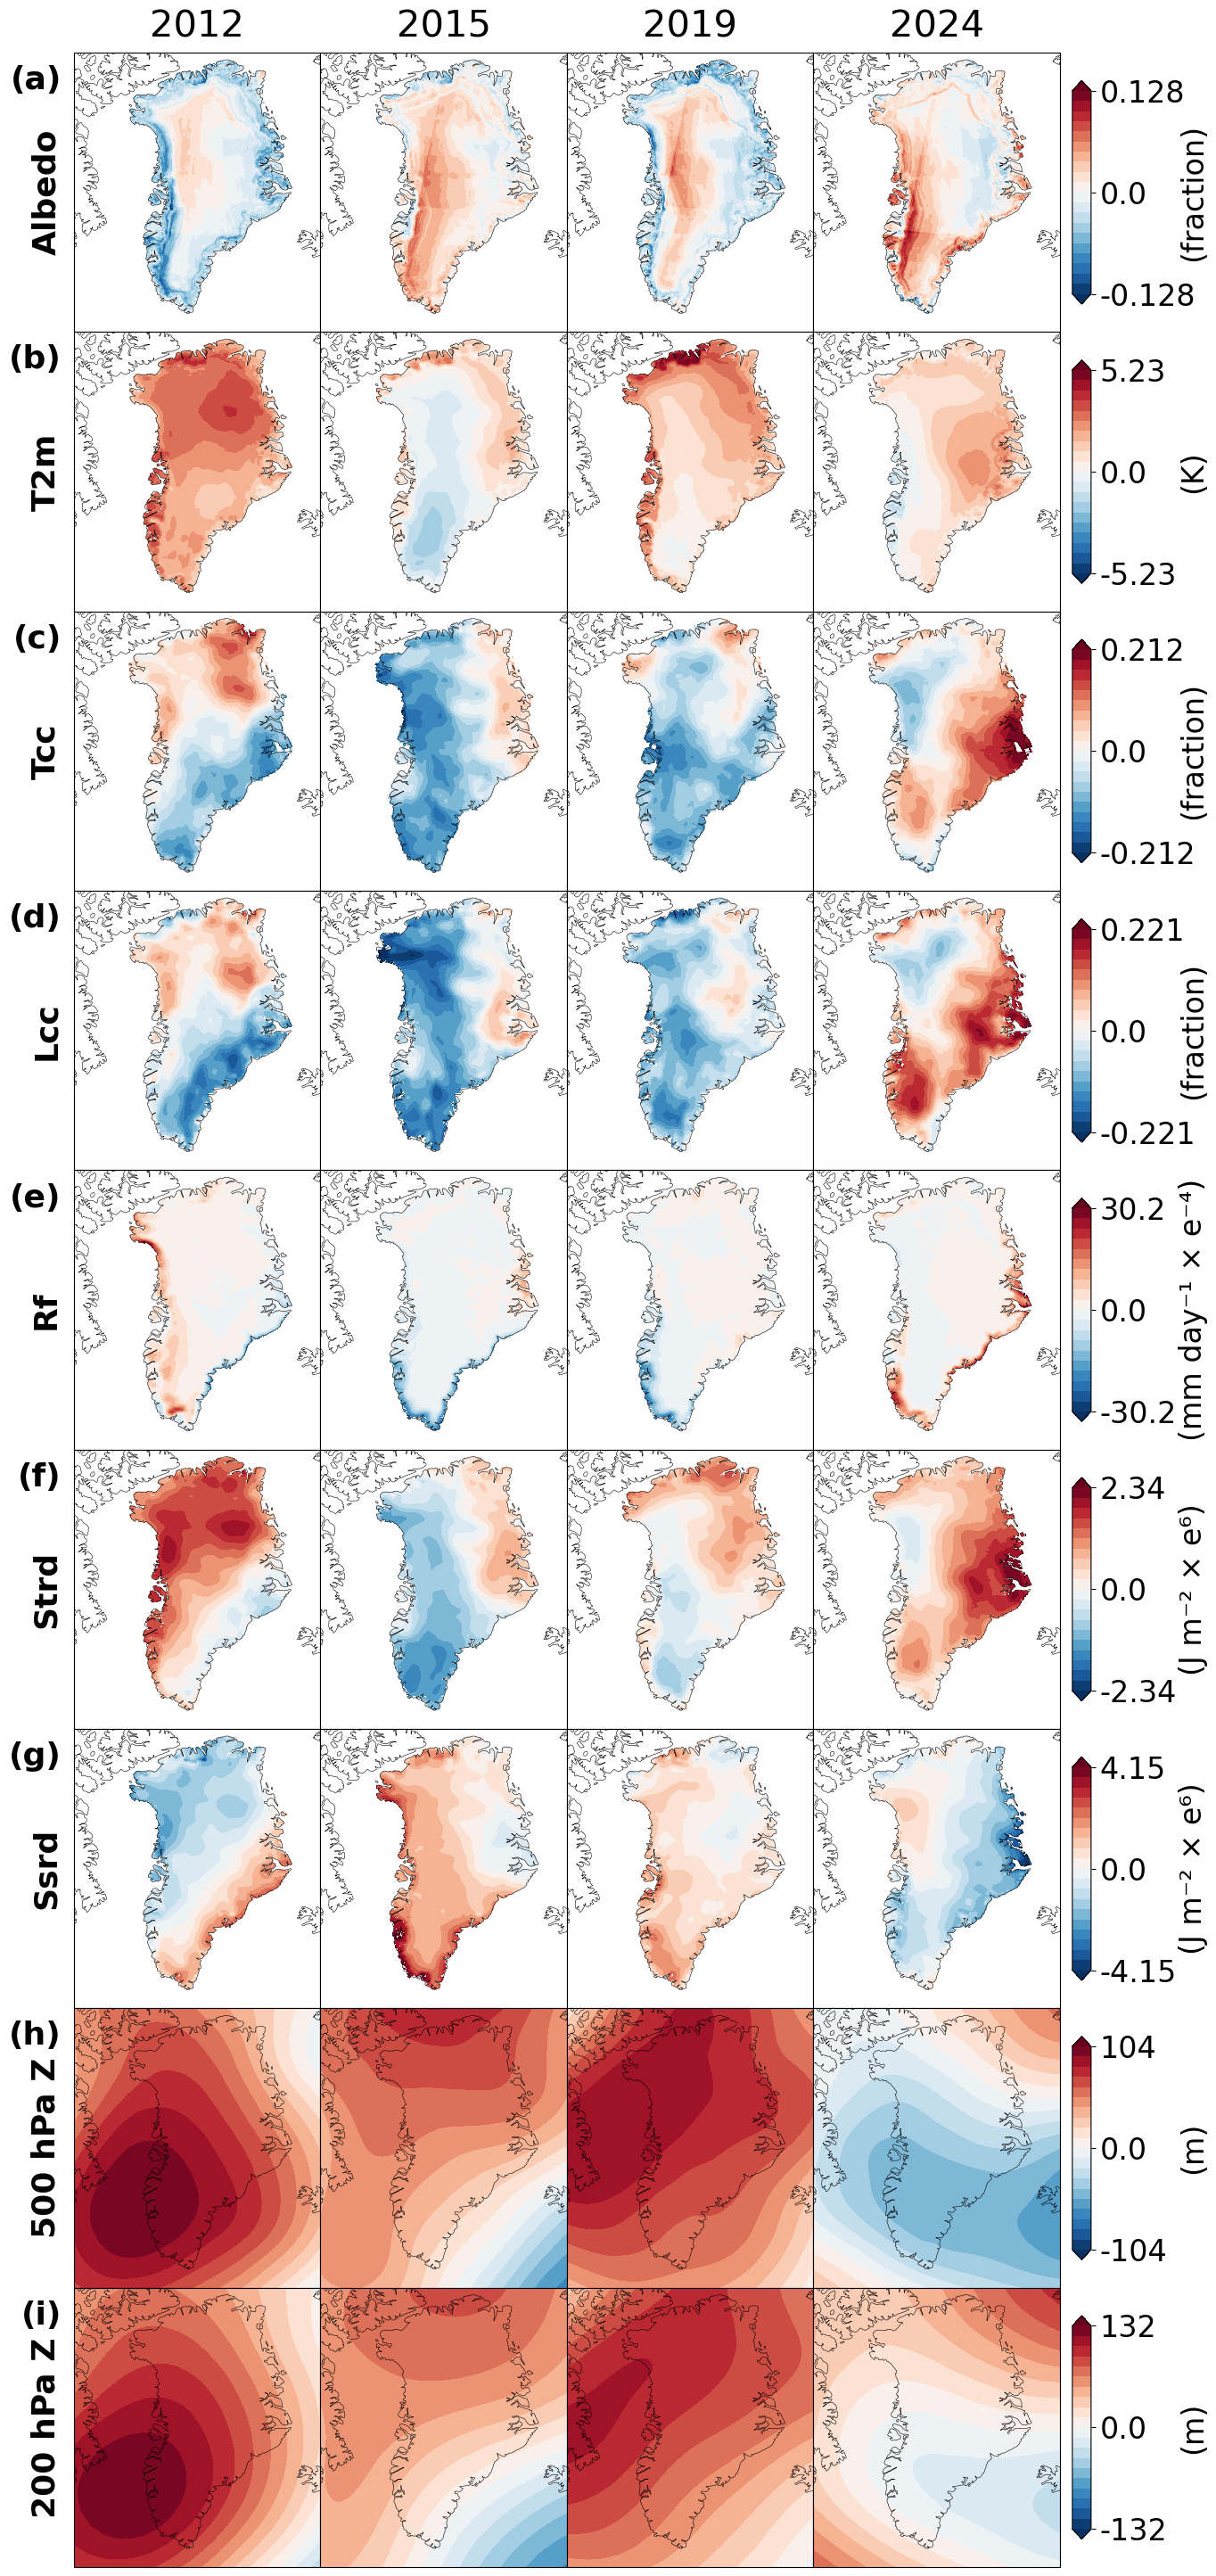

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import ScalarFormatter
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import os

# ==================== 参数 ====================
years = [2012, 2015, 2019, 2024]
clim_years = range(1981, 2011)

FIG_W = 14
FIG_H = 30
EXTENT = [-60, -25, 58, 84]
CENTRAL_LON = -40

LEFT    = 0.03
RIGHT   = 0.82
TOP     = 0.99
BOTTOM = 0.05

YEAR_FONT_SIZE   = 30
ROW_LABEL_SIZE   = 26
CBAR_LABEL_SIZE  = 24
CBAR_TICK_SIZE   = 24

CBAR_WIDTH = 0.015
CBAR_LEFT_MARGIN = 0.01

UNIT_PAD = 0.07  # 右移避免与色标数字重叠

# ==================== 文件路径 ====================
BASE_DIR = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile"
file_tccsrrdz   = os.path.join(BASE_DIR, "tccsrrdz.nc")
file_z          = os.path.join(BASE_DIR, "200500850North.nc")
file_rf_tp      = os.path.join(BASE_DIR, "sf_tp_rf.nc")
file_t2m        = os.path.join(BASE_DIR, "greenlandT2M.nc")
file_hclcvimdf  = os.path.join(BASE_DIR, "GreenlandhclcVIMF.nc")
file_alb        = r"C:\greenland\1995bu\Greenland_albedo1950-2024.nc"
file_strd       = os.path.join(BASE_DIR, "ERA5LANDfeature_greenland202209.nc")

# ==================== 时间统一模块 ====================
def open_with_timefix(path):
    ds = xr.open_dataset(path)

    if "valid_time" in ds.coords:
        ds = ds.rename({"valid_time": "time"})
    elif "time" not in ds.coords:
        for cname in ds.coords:
            if "time" in cname.lower():
                ds = ds.rename({cname: "time"})
                break

    if "time" not in ds.coords:
        ds = ds.expand_dims({"time": [np.datetime64("2000-01-01")]})
        return ds

    t = ds["time"]

    if np.issubdtype(t.dtype, np.integer):
        years = t.values.astype(int)
        ds = ds.assign_coords(time=np.array([f"{y}-07-01" for y in years],
                                            dtype="datetime64[ns]"))
        return ds

    if t.dtype.kind in {"U", "S"}:
        ds = ds.assign_coords(time=t.astype("datetime64[ns]"))
        return ds

    return ds

# ==================== lat/lon 统一 ====================
def ensure_latlon(ds):
    rename = {}
    if "latitude" in ds.coords and "lat" not in ds.coords:
        rename["latitude"] = "lat"
    if "longitude" in ds.coords and "lon" not in ds.coords:
        rename["longitude"] = "lon"
    if rename:
        ds = ds.rename(rename)
    return ds

# ==================== 距平函数 ====================
def anomalies_vs_clim(da, yrs, clim_yrs):
    ds = ensure_latlon(da.to_dataset(name="tmp"))
    da = ds["tmp"]

    jja = da.sel(time=da.time.dt.month.isin([6,7,8]))
    clim = jja.sel(time=jja.time.dt.year.isin(clim_yrs)).mean("time")

    anos = {y: jja.sel(time=jja.time.dt.year == y).mean("time") - clim
            for y in yrs}

    vmax = max(abs(float(a.max())) for a in anos.values())
    return anos, vmax

# ==================== 加载变量 ====================
with open_with_timefix(file_tccsrrdz) as ds:
    ds = ensure_latlon(ds)
    ano_tcc, vmax_tcc = anomalies_vs_clim(ds["tcc"], years, clim_years)
    ssrd = ds["ssrd"]/1e6; ssrd.name="ssrd"
    ano_ssrd, vmax_ssrd = anomalies_vs_clim(ssrd, years, clim_years)

with open_with_timefix(file_z) as ds:
    ds = ensure_latlon(ds)
    z500 = ds["z"].sel(pressure_level=500)/9.80665; z500.name="z500"
    z200 = ds["z"].sel(pressure_level=200)/9.80665; z200.name="z200"
    ano500, vmax500 = anomalies_vs_clim(z500, years, clim_years)
    ano200, vmax200 = anomalies_vs_clim(z200, years, clim_years)

with open_with_timefix(file_rf_tp) as ds:
    ds = ensure_latlon(ds)
    rf = ds["rf"]*1e4; rf.name="rf"
    ano_rf, vmaxrf = anomalies_vs_clim(rf, years, clim_years)

with open_with_timefix(file_t2m) as ds:
    ds = ensure_latlon(ds)
    ano_t2m, vmaxt2m = anomalies_vs_clim(ds["t2m"], years, clim_years)

with open_with_timefix(file_alb) as ds:
    ds = ensure_latlon(ds)
    ano_alb, vmax_alb = anomalies_vs_clim(ds["albedo"], years, clim_years)

with open_with_timefix(file_hclcvimdf) as ds:
    ds = ensure_latlon(ds)
    ano_lc, vmax_lc = anomalies_vs_clim(ds["lcc"], years, clim_years)
    ano_hc, vmax_hc = anomalies_vs_clim(ds["hcc"], years, clim_years)

with open_with_timefix(file_strd) as ds:
    ds = ensure_latlon(ds)
    strd = ds["strd"]/1e6; strd.name="strd"
    ano_strd, vmax_strd = anomalies_vs_clim(strd, years, clim_years)

# ==================== 画图 ====================
proj = ccrs.NorthPolarStereo(central_longitude=CENTRAL_LON)
fig, grid = plt.subplots(
    nrows=9, ncols=len(years),
    figsize=(FIG_W, FIG_H),
    subplot_kw={'projection': proj},
    gridspec_kw={'left':LEFT, 'right':RIGHT, 'top':TOP,
                 'bottom':BOTTOM, 'hspace':0, 'wspace':0}
)

# ==================== 绘制一行 ====================
def plot_row(row_axes, anodict, vmax, label, unit, row_idx):
    norm = TwoSlopeNorm(vmin=-vmax, vcenter=0, vmax=vmax)
    cf = None

    for ax, y in zip(row_axes, years):

        ax.set_adjustable('datalim')
        ax.set_aspect('auto')

        ax.set_extent(EXTENT, crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.COASTLINE, linewidth=0.4)
        ax.set_xticks([]); ax.set_yticks([])

        data = anodict[y]
        lon, lat = data["lon"], data["lat"]

        cf = ax.contourf(
            lon, lat, data,
            levels=np.linspace(-vmax, vmax, 21),
            cmap="RdBu_r", norm=norm,
            transform=ccrs.PlateCarree(), extend="both"
        )

    # 行标签
    pos = row_axes[0].get_position()
    label_x = pos.x0 - 0.01
    label_y = pos.y0 + pos.height / 2
    
    fig.text(
        label_x, label_y, label,
        ha='right', va='center',
        fontsize=ROW_LABEL_SIZE, weight='bold',
        rotation=90
    )
    
    # 小标题 - 向下移动1.5倍自身高度
    # 估算文字高度（相对于图形坐标）
    text_height_estimate = (ROW_LABEL_SIZE / 72) / FIG_H  # 字号转英寸再转相对坐标
    subtitle_y = pos.y0 + pos.height + 0.002 - 1.5 * text_height_estimate
    
    fig.text(
        label_x, subtitle_y, f"({chr(97 + row_idx)})",
        ha='right', va='bottom',
        fontsize=ROW_LABEL_SIZE, weight='bold'
    )

    # 色标 - 高度改为80%
    cax_height = pos.height * 0.8
    cax_y0 = pos.y0 + (pos.height - cax_height) / 2
    
    cax = fig.add_axes([RIGHT + CBAR_LEFT_MARGIN, cax_y0,
                        CBAR_WIDTH, cax_height])

    cb = fig.colorbar(cf, cax=cax, orientation='vertical')
    
    # 自定义刻度标签:中间0.0,两端最多3位有效数字
    def format_tick(val):
        if abs(val) < 1e-10:  # 接近0
            return "0.0"
        # 保留3位有效数字
        return f"{val:.3g}"
    
    tick_values = [-vmax, 0, vmax]
    tick_labels = [format_tick(v) for v in tick_values]
    
    cb.set_ticks(tick_values)
    cb.set_ticklabels(tick_labels)
    
    cb.ax.tick_params(labelsize=CBAR_TICK_SIZE)

    mid_y = cax_y0 + cax_height/2

    # 单位 - 删除了物理描述
    fig.text(
        RIGHT + CBAR_LEFT_MARGIN + CBAR_WIDTH + UNIT_PAD,
        mid_y, unit,
        rotation=90, fontsize=CBAR_LABEL_SIZE,
        ha='left', va='center'
    )

# ==================== 定义 rows（顺序已调整） ====================
# 修改说明：Z500 和 Z200 已移至列表末尾
rows = [
    (ano_alb, vmax_alb, "Albedo", "(fraction)"),
    (ano_t2m, vmaxt2m, "T2m", "(K)"),
    # 500和200原位置在此，现已移除
    (ano_tcc, vmax_tcc, "Tcc", "(fraction)"),
    (ano_lc, vmax_lc, "Lcc", "(fraction)"),
    (ano_rf, vmaxrf, "Rf", "(mm day⁻¹ × e⁻⁴)"),
    (ano_strd, vmax_strd, "Strd", "(J m⁻² × e⁶)"),
    (ano_ssrd, vmax_ssrd, "Ssrd", "(J m⁻² × e⁶)"),
    (ano500, vmax500, "500 hPa Z", "(m)"),  # 移动到倒数第二行
    (ano200, vmax200, "200 hPa Z", "(m)")   # 移动到最后一行
]

# ==================== 绘制全部行 ====================
for i, (data, vmax, label, unit) in enumerate(rows):
    plot_row(grid[i, :], data, vmax, label, unit, i)

# ==================== 年份标签 ====================
for ax, y in zip(grid[0], years):
    pos = ax.get_position()
    fig.text(
        pos.x0 + pos.width / 2,
        TOP + 0.003,
        str(y),
        fontsize=YEAR_FONT_SIZE,
        ha='center', va='bottom'
    )

plt.show()

In [2]:
import xarray as xr
import numpy as np

# ==================== 文件路径 ====================
file_uv = r"C:\Users\greenlandProject\ERA5LAND\ProcessFile\u10v10North.nc"

# ==================== 时间自动修复（与你现有风格一致） ====================
def open_with_timefix(path):
    ds = xr.open_dataset(path)

    # rename valid_time → time
    if "valid_time" in ds.coords:
        ds = ds.rename({"valid_time": "time"})
    # 找到任何含 time 字样的坐标
    elif "time" not in ds.coords:
        for cname in ds.coords:
            if "time" in cname.lower():
                ds = ds.rename({cname: "time"})
                break

    # 如果仍然没有 time → 构造
    if "time" not in ds.coords:
        ds = ds.expand_dims({"time": [np.datetime64("2000-01-01")]})
        return ds

    t = ds["time"]

    # 若是整数年份 → 转成 datetime64
    if np.issubdtype(t.dtype, np.integer):
        years = t.values.astype(int)
        ds = ds.assign_coords(time=np.array([f"{y}-07-01" for y in years],
                                            dtype="datetime64[ns]"))
        return ds

    # 若为字符串 → 强制转换
    if t.dtype.kind in {"U", "S"}:
        ds = ds.assign_coords(time=t.astype("datetime64[ns]"))
        return ds

    return ds

# ==================== 读取并检查 ====================
try:
    ds = open_with_timefix(file_uv)
except Exception as e:
    print("❌ 文件读取失败:", e)
    raise

print("\n==================== 数据集结构 ====================\n")
print(ds)

print("\n==================== 变量列表 ====================\n")
print(list(ds.data_vars))

print("\n==================== 坐标列表 ====================\n")
print(list(ds.coords))

print("\n==================== 维度信息 ====================\n")
for d in ds.dims:
    print(f"{d}: {ds.dims[d]}")

print("\n==================== 时间前10个 ====================\n")
print(ds.time.values[:10])

print("\n==================== 各变量数值范围 ====================\n")
for v in ds.data_vars:
    arr = ds[v]
    try:
        print(f"{v}: [{float(arr.min()):.3f}, {float(arr.max()):.3f}]")
    except:
        print(f"{v}: 无法计算（可能是非数值变量）")



==================== 数据集结构 ====================

<xarray.Dataset> Size: 24GB
Dimensions:    (time: 910, latitude: 901, longitude: 3600)
Coordinates:
    number     int64 8B ...
  * time       (time) datetime64[ns] 7kB 1950-01-01 1950-02-01 ... 2025-10-01
  * latitude   (latitude) float64 7kB 90.0 89.9 89.8 89.7 ... 0.3 0.2 0.1 0.0
  * longitude  (longitude) float64 29kB -180.0 -179.9 -179.8 ... 179.8 179.9
    expver     (time) <U4 15kB ...
Data variables:
    u10        (time, latitude, longitude) float32 12GB ...
    v10        (time, latitude, longitude) float32 12GB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-11-30T14:39 GRIB to CDM+CF via cfgrib-0.9.1...

==================== 变量列表 ====================

['u10', 'v10']


C:\Users\11823\AppData\Local\Temp\ipykernel_9624\2336544353.py:60: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f"{d}: {ds.dims[d]}")


u10: [-14.330, 12.226]
v10: [-14.457, 12.737]
